# 01. Persiapan Deret Waktu Harian

**Tujuan:** menghasilkan deret waktu harian yang bersih dan kontinu untuk setiap komoditas, lengkap dengan pemahaman karakteristiknya (tren dan musiman), sebagai masukan notebook backtest model.

**Alur:**
1. Data loading dan pemeriksaan kualitas
2. Persiapan deret waktu harian
3. Visualisasi harga harian
4. Eksplorasi tren dan pola musiman
5. STL decomposition (periode 7, 30, 365)
6. Persiapan dataset forecasting

Uji stasioneritas (ADF dan KPSS) tidak dilakukan di notebook ini. Pengujian akan dilakukan pada notebook backtest dengan data latih saja, karena hasilnya menjadi dasar penentuan orde differencing model.

**Paket:** `pandas`, `numpy`, `matplotlib`, `statsmodels`. Opsional: `holidays` (fitur hari libur).

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

try:
    import holidays
    HOLIDAYS_OK = True
except ImportError:
    HOLIDAYS_OK = False

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)


# ---------- Lokasi proyek (tidak bergantung kedalaman folder notebook) ----------
def cari_root(penanda=("data", "processed")):
    mulai = Path.cwd().resolve()
    for p in (mulai, *mulai.parents):
        if p.joinpath(*penanda).exists():
            return p
    raise FileNotFoundError(f"Folder {'/'.join(penanda)} tidak ditemukan dari {mulai}")


ROOT = cari_root()
DATA_10 = ROOT / "data" / "processed" / "harga_10_komoditas.csv"
OUT_DATA = ROOT / "data" / "processed" / "forecasting"
OUT_TABEL = ROOT / "reports" / "tables" / "forecasting"
OUT_GAMBAR = ROOT / "reports" / "figures" / "forecasting"
for p in (OUT_DATA, OUT_TABEL, OUT_GAMBAR, OUT_GAMBAR / "stl"):
    p.mkdir(parents=True, exist_ok=True)
assert DATA_10.exists(), f"File tidak ditemukan: {DATA_10}"

# ---------- Parameter data ----------
MAKS_ISI_HARI = 30            # lubang <= 30 hari diisi interpolasi
MIN_HARI_LATIH = 730          # peringatan jika deret < ~2 tahun
PCT_DIISI_WASPADA = 5         # peringatan jika > 5% hari hasil interpolasi

# ---------- Parameter STL ----------
PERIODE_STL = (7, 30, 365)    # mingguan, bulanan (aproksimasi), tahunan
MIN_SIKLUS = 3                # periode dipakai hanya jika data memuat >= 3 siklus penuh
                              # (periode 365 butuh >= 1.095 hari; kalau kurang, otomatis dilewati)
AMBANG_MINIMAL = 0.10         # kekuatan musiman minimal agar dianggap bermakna secara praktis
N_SURROGAT = 10               # deret tiruan untuk ambang (naikkan ke 30-50 untuk hasil final)
STL_ROBUST = False            # False = jauh lebih cepat; True hanya untuk hasil final
STL_JUMP = True               # percepat LOESS dengan interpolasi (jump disesuaikan dengan periode)
N_JOBS = -1                   # -1 = semua core CPU (dipakai untuk surrogat paralel)
SEED = 42

# ---------- Parameter kalender dan tampilan ----------
KALENDER_KE_DEPAN = 7         # hari fitur kalender setelah data terakhir; HORIZON di notebook backtest tidak boleh melebihi nilai ini
TAMPILKAN_STL = 2             # jumlah komoditas yang gambar STL-nya ditampilkan (semua tetap disimpan)

NAMA_HARI = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]
NAMA_BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

# ---------- Validasi parameter ----------
assert KALENDER_KE_DEPAN >= 1
assert 0 <= AMBANG_MINIMAL <= 1


# ---------- Konfigurasi STL tunggal: dipakai untuk data asli DAN surrogat ----------
def stl_kwargs(periode):
    """Satu sumber pengaturan STL agar ambang surrogat sebanding dengan data asli."""
    j = max(1, periode // 7) if STL_JUMP else 1
    return dict(period=periode, robust=STL_ROBUST,
                seasonal_jump=j, trend_jump=j, low_pass_jump=j)


def cukup_siklus(n_data, periode):
    return n_data >= MIN_SIKLUS * periode


print("Folder proyek :", ROOT)
print("Paket holidays:", "ada" if HOLIDAYS_OK else "tidak ada")
print(f"STL           : robust={STL_ROBUST}, jump={STL_JUMP}, surrogat={N_SURROGAT}, n_jobs={N_JOBS}")

Folder proyek : D:\STUDY\SEMESTER 5\magang\proyek\siperkom-dashboard
Paket holidays: ada
STL           : robust=False, jump=True, surrogat=10, n_jobs=-1


### 1. Data loading dan pemeriksaan kualitas

In [2]:
raw = pd.read_csv(DATA_10, parse_dates=["tanggal"])
kolom_wajib = {"tanggal", "komoditas", "satuan", "harga", "anomali"}
assert kolom_wajib <= set(raw.columns), f"Kolom kurang: {kolom_wajib - set(raw.columns)}"
raw["anomali"] = raw["anomali"].astype(bool)

print(f"Baris: {len(raw):,} | Komoditas: {raw['komoditas'].nunique()} | "
      f"Periode: {raw['tanggal'].min().date()} s.d. {raw['tanggal'].max().date()}")

satuan = raw.groupby("komoditas")["satuan"].nunique()
assert (satuan == 1).all(), f"Satuan ganda pada: {list(satuan[satuan > 1].index)}"
print(f"Duplikat (tanggal, komoditas): {int(raw.duplicated(['tanggal', 'komoditas']).sum())}")
print(f"Harga kosong atau <= 0        : {int((raw['harga'].isna() | (raw['harga'] <= 0)).sum())}")

ringkas_mentah = (raw.groupby("komoditas")
                  .agg(satuan=("satuan", "first"), mulai=("tanggal", "min"), akhir=("tanggal", "max"),
                       n_baris=("harga", "size"), n_anomali=("anomali", "sum"),
                       harga_min=("harga", "min"), harga_median=("harga", "median"), harga_maks=("harga", "max"))
                  .sort_index())
ringkas_mentah

Baris: 13,350 | Komoditas: 10 | Periode: 2023-01-01 s.d. 2026-08-31
Duplikat (tanggal, komoditas): 0
Harga kosong atau <= 0        : 0


,satuan,mulai,akhir,n_baris,n_anomali,harga_min,harga_median,harga_maks
komoditas,,,,,,,,
Bawang Bombay,Kg,2023-01-01,2026-08-31,1335,0,21000.000000,31857.142860,45000.000000
Bayam (Jenis Sayur),Ikat Kecil,2023-01-01,2026-08-31,1335,0,1500.000000,1916.666667,4000.000000
Buncis,Kg,2023-01-01,2026-08-31,1335,2,9857.142857,13666.666667,31571.428570
Kacang Kedelai (Kualitas Lokal),Kg,2023-01-01,2026-08-31,1335,0,12333.333330,14250.000000,19166.666670
Kangkung (Jenis Panjang),Ikat Kecil,2023-01-01,2026-08-31,1335,0,1333.333333,1583.333333,4833.333333
Kubis,Kg,2023-01-01,2026-08-31,1335,1,6000.000000,8166.666667,20714.285710
Sawi (Jenis Hijau),Ikat Kecil,2023-01-01,2026-08-31,1335,0,1700.000000,2166.666667,2900.000000
Terong Ungu (Jenis Sayur),Kg,2023-01-01,2026-08-31,1335,0,6000.000000,8571.428571,10400.000000
Tomat,Kg,2023-01-01,2026-08-31,1335,0,5000.000000,11571.428570,29142.857140


### 2. Persiapan deret waktu harian

1. Harga di hari `anomali` dijadikan kosong.
2. Semua komoditas dipetakan ke kalender harian penuh, sehingga hari yang tidak tercatat terlihat sebagai kosong.
3. Lubang **≤ `MAKS_ISI_HARI`** diisi interpolasi linear berbasis waktu. Lubang yang lebih panjang tidak diisi sebagian: bila ada, deret dipotong dan dipakai mulai setelah lubang terakhir.
4. Setiap hari diberi status `asli` atau `interpolasi`. Saat evaluasi model, galat dihitung hanya pada hari `asli`.

In [3]:
def panjang_lubang(kosong):
    """Panjang tiap rentetan hari kosong berurutan (kosong = Series boolean)."""
    grup = (kosong != kosong.shift()).cumsum()
    p = kosong.groupby(grup).sum()
    return p[p > 0]


raw["harga_bersih"] = raw["harga"].where(~raw["anomali"])
wide = raw.pivot_table(index="tanggal", columns="komoditas", values="harga_bersih", aggfunc="mean")
kalender = pd.date_range(wide.index.min(), wide.index.max(), freq="D")
wide = wide.reindex(kalender)

hasil, profil = [], []
for nama in wide.columns:
    s = wide[nama]
    s = s.loc[s.first_valid_index(): s.last_valid_index()]       # buang kosong di awal dan akhir
    kosong = s.isna()
    p_asli = panjang_lubang(kosong)

    interp = s.interpolate(method="time", limit_area="inside")
    panjang = kosong.groupby((kosong != kosong.shift()).cumsum()).transform("sum")
    boleh_isi = kosong & (panjang <= MAKS_ISI_HARI)               # hanya lubang yang utuh <= batas
    h = s.copy()
    h[boleh_isi] = interp[boleh_isi]
    status = pd.Series("asli", index=s.index)
    status[boleh_isi] = "interpolasi"

    hari_dipotong = 0
    if h.isna().any():                                            # lubang > batas: pakai segmen kontinu terakhir
        mulai = h.index[h.isna()][-1] + pd.Timedelta(days=1)
        hari_dipotong = int((mulai - h.index[0]).days)
        h, status = h.loc[mulai:], status.loc[mulai:]

    hasil.append(pd.DataFrame({"tanggal": h.index, "komoditas": nama, "harga": h.values, "status": status.values}))
    profil.append({
        "komoditas": nama, "satuan": raw.loc[raw["komoditas"] == nama, "satuan"].iloc[0],
        "mulai": h.index[0].date(), "akhir": h.index[-1].date(), "n_hari": len(h),
        "n_asli": int((status == "asli").sum()), "n_interpolasi": int((status == "interpolasi").sum()),
        "pct_diisi": round((status == "interpolasi").mean() * 100, 2),
        "lubang_terpanjang": int(p_asli.max()) if len(p_asli) else 0,
        "hari_dipotong_awal": hari_dipotong,
        "ubah_harian_maks_pct": round(h.pct_change().abs().max() * 100, 1),
    })

deret = pd.concat(hasil, ignore_index=True)
profil = pd.DataFrame(profil).set_index("komoditas")

# Validasi: kontinu harian, tanpa kosong, harga positif
for nama, g in deret.groupby("komoditas"):
    assert g["harga"].notna().all() and (g["harga"] > 0).all(), f"{nama}: harga kosong atau <= 0"
    assert (g["tanggal"].diff().dropna() == pd.Timedelta(days=1)).all(), f"{nama}: tanggal tidak kontinu"

seri = {nama: g.set_index("tanggal")["harga"] for nama, g in deret.groupby("komoditas")}
status_seri = {nama: g.set_index("tanggal")["status"] for nama, g in deret.groupby("komoditas")}
komoditas_list = list(seri)

print("Validasi lolos: semua deret kontinu harian, tanpa kosong, harga positif.\n")
for nama, r in profil.iterrows():
    if r["n_hari"] < MIN_HARI_LATIH:
        print(f"PERINGATAN {nama}: deret hanya {r['n_hari']} hari (< {MIN_HARI_LATIH})")
    if r["pct_diisi"] > PCT_DIISI_WASPADA:
        print(f"PERINGATAN {nama}: {r['pct_diisi']}% hari hasil interpolasi (> {PCT_DIISI_WASPADA}%)")
    if r["hari_dipotong_awal"] > 0:
        print(f"PERINGATAN {nama}: {r['hari_dipotong_awal']} hari awal dibuang karena ada lubang > {MAKS_ISI_HARI} hari")
profil

Validasi lolos: semua deret kontinu harian, tanpa kosong, harga positif.



,satuan,mulai,akhir,n_hari,n_asli,n_interpolasi,pct_diisi,lubang_terpanjang,hari_dipotong_awal,ubah_harian_maks_pct
komoditas,,,,,,,,,,
Bawang Bombay,Kg,2023-01-01,2026-08-31,1339,1335,4,0.30,3,0,59.2
Bayam (Jenis Sayur),Ikat Kecil,2023-01-01,2026-08-31,1339,1335,4,0.30,3,0,71.4
Buncis,Kg,2023-01-01,2026-08-31,1339,1333,6,0.45,3,0,34.6
Kacang Kedelai (Kualitas Lokal),Kg,2023-01-01,2026-08-31,1339,1335,4,0.30,3,0,35.3
Kangkung (Jenis Panjang),Ikat Kecil,2023-01-01,2026-08-31,1339,1335,4,0.30,3,0,69.6
Kubis,Kg,2023-01-01,2026-08-31,1339,1334,5,0.37,3,0,47.6
Sawi (Jenis Hijau),Ikat Kecil,2023-01-01,2026-08-31,1339,1335,4,0.30,3,0,25.0
Terong Ungu (Jenis Sayur),Kg,2023-01-01,2026-08-31,1339,1335,4,0.30,3,0,33.3
Tomat,Kg,2023-01-01,2026-08-31,1339,1335,4,0.30,3,0,93.5


### 3. Visualisasi harga harian
Garis biru = harga harian, garis oranye = rata-rata bergulir 30 hari, titik merah = hari hasil interpolasi.

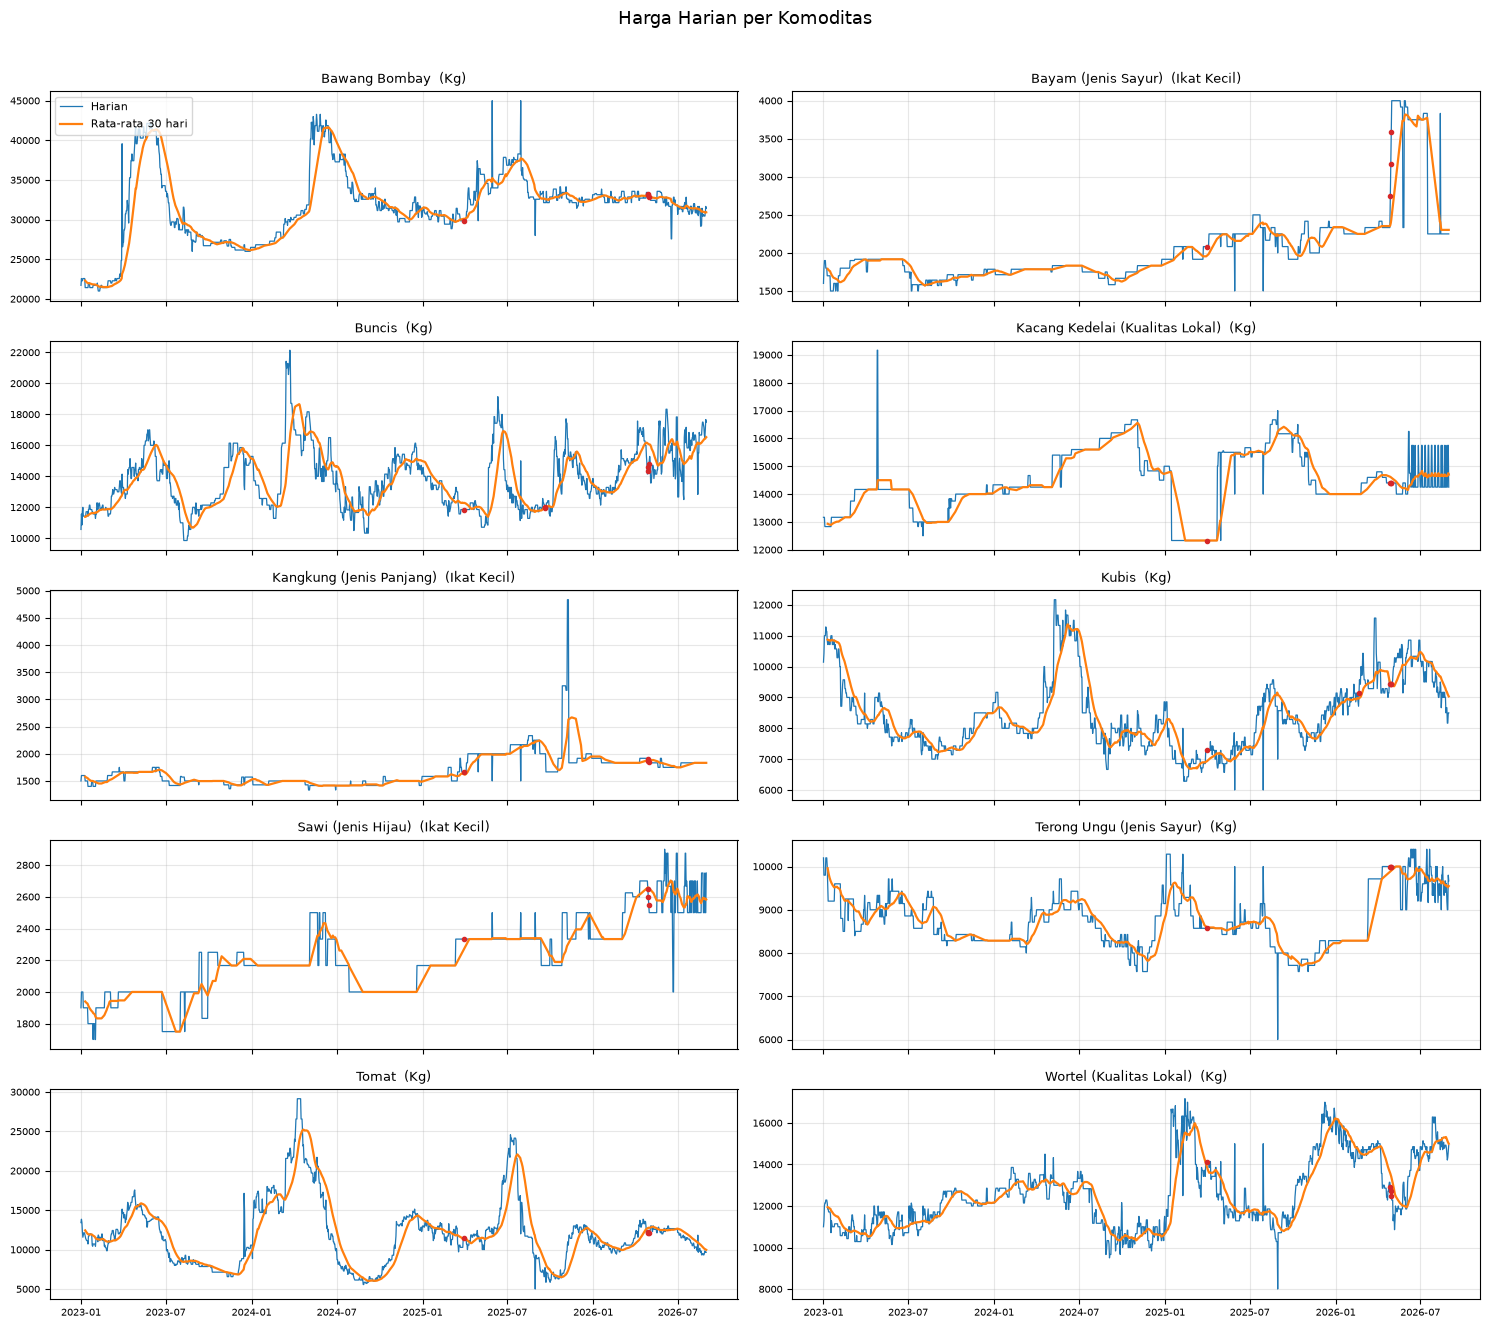

In [4]:
n = len(komoditas_list)
baris_n = int(np.ceil(n / 2))
fig, axes = plt.subplots(baris_n, 2, figsize=(15, 2.7 * baris_n), sharex=True)
axes = axes.ravel()
for ax, nama in zip(axes, komoditas_list):
    h = seri[nama]
    ax.plot(h.index, h.values, color="#1f77b4", linewidth=0.9, label="Harian")
    ax.plot(h.index, h.rolling(30, min_periods=10).mean(), color="#ff7f0e", linewidth=1.6, label="Rata-rata 30 hari")
    diisi = h[status_seri[nama] != "asli"]
    ax.scatter(diisi.index, diisi.values, color="#d62728", s=9, zorder=3)
    ax.set_title(f"{nama}  ({profil.at[nama, 'satuan']})", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3)
for ax in axes[n:]:
    ax.axis("off")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Harga Harian per Komoditas", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(OUT_GAMBAR / "harga_harian.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Eksplorasi tren dan pola musiman

- **Tren:** kemiringan regresi linear pada log-harga (persen per bulan) dan R². R² rendah berarti harga tidak bergerak searah secara konsisten.
- **Pola mingguan:** harga dibagi rata-rata bergulir terpusat 7 hari, lalu dirata-ratakan per hari dalam minggu. Nilai = penyimpangan (%) dari harga rata-rata minggu itu.
- **Pola bulanan:** rata-rata harga bulanan dibagi rata-rata bergulir terpusat 13 bulan, lalu dirata-ratakan per bulan kalender. Dengan data < 4 tahun, tiap bulan hanya punya 2 sampai 3 pengamatan, jadi bacalah sebagai **indikasi**, bukan kepastian.

Pengamatan per bulan kalender (rata-rata): 2.7 tahun


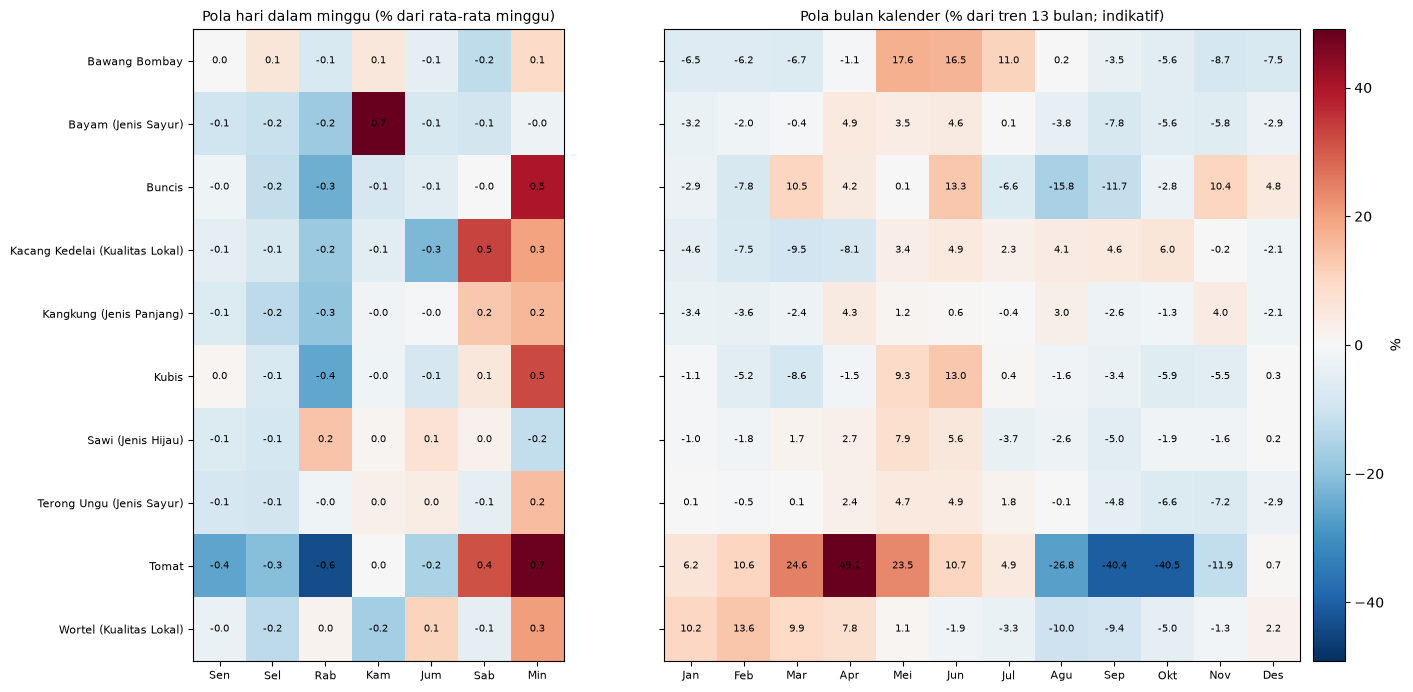

,tren_pct_per_bulan,r2_tren,ubah_total_pct,arah_tren,rentang_mingguan_pct,rentang_bulanan_pct
komoditas,,,,,,
Bawang Bombay,0.43,0.14,41.72,tanpa tren jelas,0.30,26.25
Bayam (Jenis Sayur),1.18,0.54,39.28,naik,0.93,12.66
Buncis,0.26,0.06,42.19,tanpa tren jelas,0.88,29.04
Kacang Kedelai (Kualitas Lokal),0.17,0.08,12.98,tanpa tren jelas,0.76,15.50
Kangkung (Jenis Panjang),0.72,0.36,23.32,naik,0.49,7.89
Kubis,0.18,0.03,-16.25,tanpa tren jelas,0.80,21.59
Sawi (Jenis Hijau),0.66,0.64,38.89,naik,0.36,12.89
Terong Ungu (Jenis Sayur),0.03,0.00,0.15,tanpa tren jelas,0.33,12.12
Tomat,-0.05,0.00,-14.56,tanpa tren jelas,1.27,89.57


In [5]:
# ---------- 4a. Tren ----------
baris = []
for nama, h in seri.items():
    x = (h.index - h.index[0]).days.values.astype(float)
    slope = np.polyfit(x, np.log(h.values), 1)[0]
    r2 = np.corrcoef(x, np.log(h.values))[0, 1] ** 2
    baris.append({"komoditas": nama,
                  "tren_pct_per_bulan": (np.exp(slope * 30.44) - 1) * 100,
                  "r2_tren": r2,
                  "ubah_total_pct": (h.iloc[-30:].mean() / h.iloc[:30].mean() - 1) * 100})
tren = pd.DataFrame(baris).set_index("komoditas")
tren["arah_tren"] = np.where(tren["r2_tren"] < 0.30, "tanpa tren jelas",
                             np.where(tren["tren_pct_per_bulan"] > 0, "naik", "turun"))

# ---------- 4b. Pola hari dalam minggu ----------
mingguan = {}
for nama, h in seri.items():
    rasio = h / h.rolling(7, center=True).mean()
    mingguan[nama] = (rasio.groupby(rasio.index.day_of_week).mean() - 1) * 100
mingguan = pd.DataFrame(mingguan).T.reindex(columns=range(7))
mingguan.columns = NAMA_HARI
tren["rentang_mingguan_pct"] = mingguan.max(axis=1) - mingguan.min(axis=1)

# ---------- 4c. Pola bulan kalender ----------
bulanan, n_obs = {}, {}
for nama, h in seri.items():
    m = h.resample("MS").mean()
    rasio = (m / m.rolling(13, center=True).mean()).dropna()
    bulanan[nama] = (rasio.groupby(rasio.index.month).mean() - 1) * 100
    n_obs[nama] = rasio.groupby(rasio.index.month).size()
bulanan = pd.DataFrame(bulanan).T.reindex(columns=range(1, 13))
bulanan.columns = NAMA_BULAN
tren["rentang_bulanan_pct"] = bulanan.max(axis=1) - bulanan.min(axis=1)
print(f"Pengamatan per bulan kalender (rata-rata): {pd.DataFrame(n_obs).mean().mean():.1f} tahun")


def heatmap(ax, df, judul, vmax=None):
    vmax = vmax or float(np.nanmax(np.abs(df.values)))
    im = ax.imshow(df.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(df.shape[1])); ax.set_xticklabels(df.columns, fontsize=8)
    ax.set_yticks(range(df.shape[0])); ax.set_yticklabels(df.index, fontsize=8)
    ax.set_title(judul, fontsize=10)
    return im


fig, axes = plt.subplots(1, 2, figsize=(17, 0.6 * len(seri) + 2.2), gridspec_kw={"width_ratios": [7, 12]})
heatmap(axes[0], mingguan.iloc[:, :7], "Pola hari dalam minggu (% dari rata-rata minggu)")
im = heatmap(axes[1], bulanan, "Pola bulan kalender (% dari tren 13 bulan; indikatif)")
axes[1].set_yticklabels([])
fig.colorbar(im, ax=axes, pad=0.01, label="%")
fig.savefig(OUT_GAMBAR / "pola_musiman.png", dpi=150, bbox_inches="tight")
plt.show()
tren.round(2)

## 5. STL decomposition (periode 7, 30, 365)

STL memecah harga menjadi **tren + musiman + sisa** (aditif). Secara bawaan `STL_ROBUST = False` agar proses jauh lebih cepat; ubah menjadi `True` untuk hasil final agar lonjakan tidak merusak komponen musiman.

- **Periode 7:** pola mingguan. **30:** pola bulanan (aproksimasi, karena bulan tidak persis 30 hari). **365:** pola tahunan.
- Setiap periode dipakai hanya bila data memuat minimal `MIN_SIKLUS` (3) siklus penuh. Periode 7 butuh 21 hari, periode 30 butuh 90 hari, dan periode 365 butuh 1.095 hari (3 tahun); bila kurang, periode tersebut dilewati.
- **Kekuatan musiman** (Fs) = `1 − Var(sisa) / Var(musiman + sisa)`, bernilai 0 sampai 1. Mendekati 1 berarti pola kuat.
- **Mengapa perlu pembanding acak:** harga yang bergerak naik-turun (*random walk*) tanpa musiman sama sekali pun bisa menghasilkan Fs tinggi, terutama pada periode 365 dengan data < 4 tahun (hanya 3 sampai 4 siklus). Karena itu Fs nyata dibandingkan dengan Fs dari **deret tiruan**: selisih harian deret itu diacak ulang (tren dan sebaran lonjakan sama, musiman hilang), diulang `N_SURROGAT` kali. Pola dianggap **ada** hanya bila Fs nyata melampaui persentil 95 deret tiruan (`ambang_p`) dan minimal `AMBANG_MINIMAL`.

**Catatan:** kolom `musiman_dominan` pada tabel `stl_tabel` bersifat deskriptif. Kolom ini hanya meringkas periode musiman yang paling menonjol terhadap ambang acak, sehingga tidak boleh dipakai sebagai masukan (fitur) model peramalan.

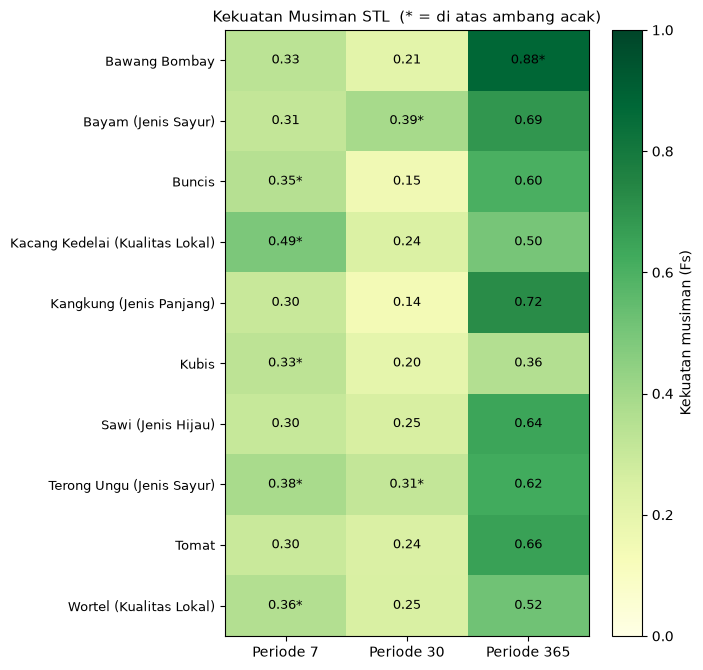

Catatan: musiman_dominan bersifat deskriptif, bukan masukan model.


,Fs_7,ambang_7,amplitudo_7_pct,Fs_30,ambang_30,amplitudo_30_pct,Fs_365,ambang_365,amplitudo_365_pct,musiman_dominan
komoditas,,,,,,,,,,
Bawang Bombay,0.333,0.345,16.15,0.210,0.267,12.01,0.878,0.779,64.62,periode 365
Bayam (Jenis Sayur),0.309,0.349,30.45,0.387,0.311,88.91,0.689,0.841,85.52,periode 30
Buncis,0.350,0.320,14.89,0.155,0.244,32.42,0.603,0.696,55.71,periode 7
Kacang Kedelai (Kualitas Lokal),0.490,0.324,11.91,0.242,0.250,15.47,0.500,0.652,39.05,periode 7
Kangkung (Jenis Panjang),0.297,0.412,43.11,0.142,0.368,28.34,0.720,0.739,173.90,tidak jelas
Kubis,0.331,0.314,12.41,0.197,0.254,14.67,0.359,0.705,50.25,periode 7
Sawi (Jenis Hijau),0.304,0.349,13.33,0.250,0.301,15.12,0.642,0.706,32.02,tidak jelas
Terong Ungu (Jenis Sayur),0.383,0.357,10.38,0.312,0.282,11.81,0.623,0.805,26.09,periode 30
Tomat,0.296,0.339,26.73,0.243,0.278,41.84,0.655,0.743,143.43,tidak jelas


In [6]:
from joblib import Parallel, delayed
def jalankan_stl(h, periode):
    if not cukup_siklus(len(h), periode):
        return None
    return STL(h, **stl_kwargs(periode)).fit()
def kekuatan_musiman(res):
    return max(0.0, 1 - res.resid.var() / (res.seasonal + res.resid).var())


def _satu_surrogat(d, awal, indeks, periode, seed):
    r = np.random.default_rng(seed)
    tiruan = pd.Series(awal + np.concatenate([[0.0], np.cumsum(r.permutation(d))]), index=indeks)
    return kekuatan_musiman(jalankan_stl(tiruan, periode))
rng = np.random.default_rng(SEED)

def ambang_acak(h, periode):
    """Persentil 95 kekuatan musiman dari deret tiruan (selisih harian diacak, musiman hilang)."""
    d = h.diff().dropna().values
    seeds = rng.integers(0, 2**31 - 1, size=N_SURROGAT)
    nilai = Parallel(n_jobs=N_JOBS)(
        delayed(_satu_surrogat)(d, h.iloc[0], h.index, periode, int(s)) for s in seeds
    )
    return float(np.percentile(nilai, 95))

stl_hasil = {}
baris = []
for nama, h in seri.items():
    r = {"komoditas": nama}
    for p in PERIODE_STL:
        res = jalankan_stl(h, p)
        stl_hasil[(nama, p)] = res
        r[f"Fs_{p}"] = round(kekuatan_musiman(res), 3) if res is not None else np.nan
        r[f"ambang_{p}"] = round(ambang_acak(h, p), 3) if res is not None else np.nan
        r[f"amplitudo_{p}_pct"] = (round((res.seasonal.max() - res.seasonal.min()) / h.mean() * 100, 2)
                                   if res is not None else np.nan)
    baris.append(r)
stl_tabel = pd.DataFrame(baris).set_index("komoditas")

kolom_fs = [f"Fs_{p}" for p in PERIODE_STL]


def musiman_ada(row, p):
    fs, amb = row[f"Fs_{p}"], row[f"ambang_{p}"]
    return pd.notna(fs) and fs > amb and fs >= AMBANG_MINIMAL


def dominan(row):
    ada = [p for p in PERIODE_STL if musiman_ada(row, p)]
    if not ada:
        return "tidak jelas"
    return f"periode {max(ada, key=lambda p: row[f'Fs_{p}'] - row[f'ambang_{p}'])}"


stl_tabel["musiman_dominan"] = stl_tabel.apply(dominan, axis=1)

# Ringkasan kekuatan musiman
fig, ax = plt.subplots(figsize=(7, 0.5 * len(stl_tabel) + 1.8))
im = ax.imshow(stl_tabel[kolom_fs].astype(float).values, cmap="YlGn", vmin=0, vmax=1, aspect="auto")
for i in range(len(stl_tabel)):
    for j, k in enumerate(kolom_fs):
        v = stl_tabel.iat[i, stl_tabel.columns.get_loc(k)]
        tanda = "*" if musiman_ada(stl_tabel.iloc[i], PERIODE_STL[j]) else ""
        ax.text(j, i, "-" if pd.isna(v) else f"{v:.2f}{tanda}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(len(kolom_fs))); ax.set_xticklabels([f"Periode {p}" for p in PERIODE_STL])
ax.set_yticks(range(len(stl_tabel))); ax.set_yticklabels(stl_tabel.index, fontsize=9)
fig.colorbar(im, ax=ax, label="Kekuatan musiman (Fs)")
ax.set_title("Kekuatan Musiman STL  (* = di atas ambang acak)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_GAMBAR / "stl_kekuatan_musiman.png", dpi=150, bbox_inches="tight")
plt.show()
print("Catatan: musiman_dominan bersifat deskriptif, bukan masukan model.")
stl_tabel


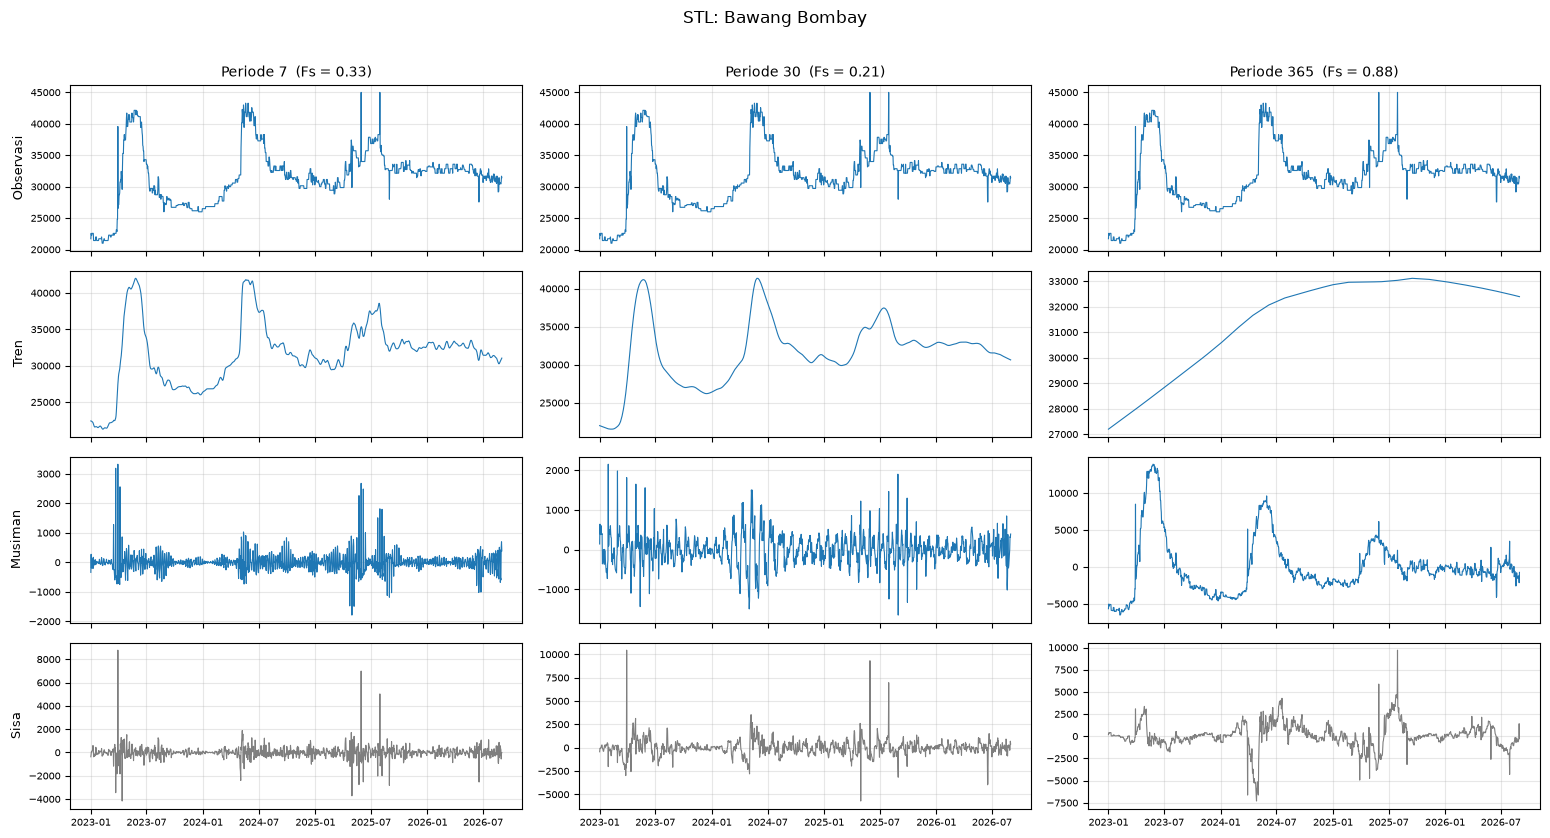

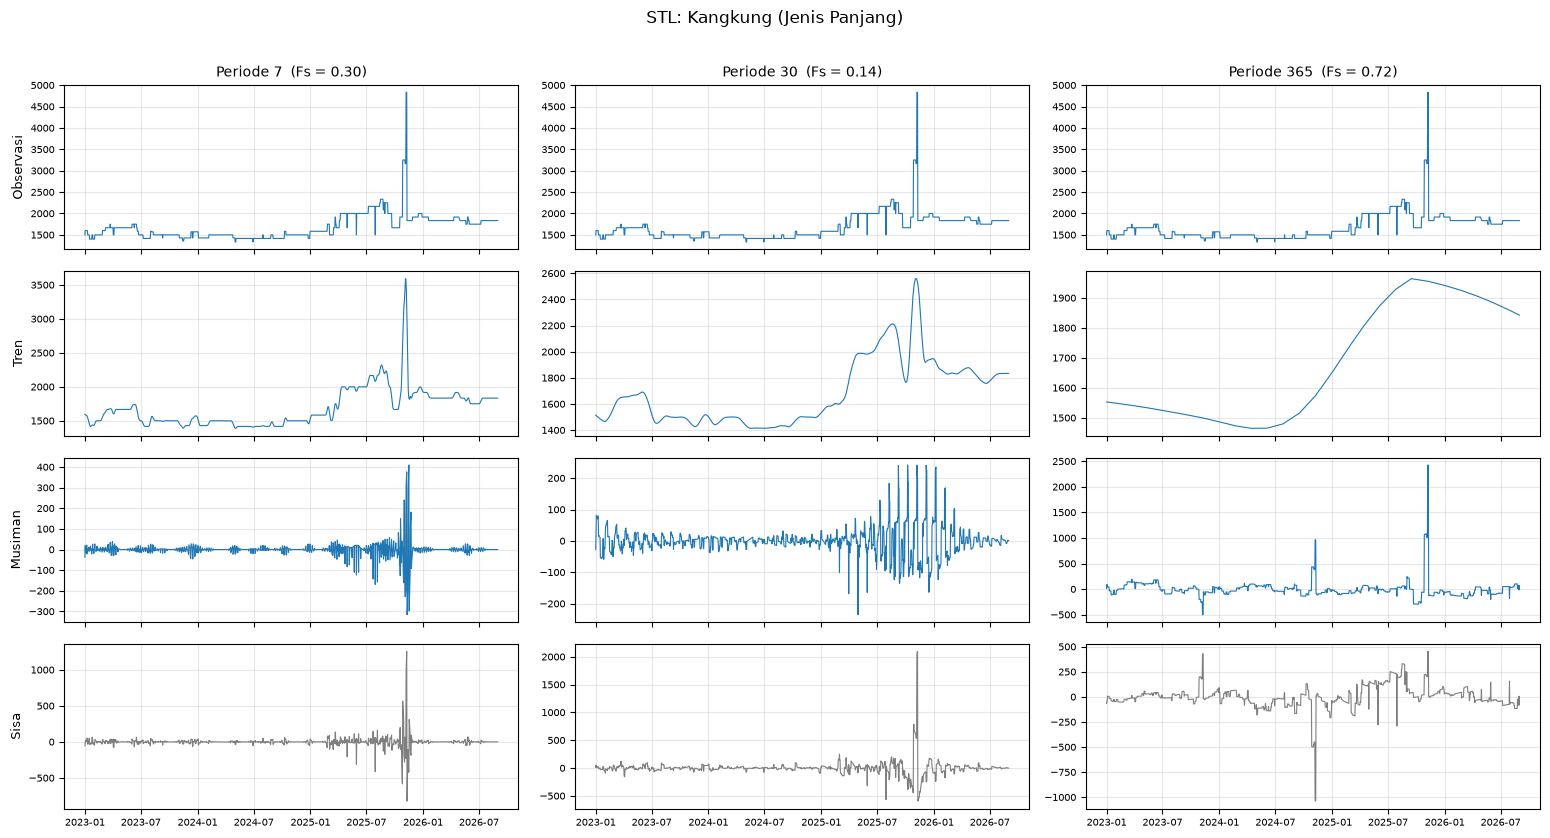

Gambar STL 10 komoditas tersimpan di: D:\STUDY\SEMESTER 5\magang\proyek\siperkom-dashboard\reports\figures\forecasting\stl


In [7]:
# Gambar dekomposisi per komoditas (4 baris x 3 periode). Semua disimpan, sebagian ditampilkan.
urut_tampil = stl_tabel[kolom_fs].max(axis=1).sort_values(ascending=False).index


def gambar_stl(nama):
    fig, axes = plt.subplots(4, len(PERIODE_STL), figsize=(5.2 * len(PERIODE_STL), 8.5), sharex=True)
    for j, p in enumerate(PERIODE_STL):
        res = stl_hasil[(nama, p)]
        if res is None:
            for i in range(4):
                axes[i, j].axis("off")
            axes[0, j].text(0.5, 0.5, f"Periode {p}: data < {MIN_SIKLUS * p} hari", ha="center", transform=axes[0, j].transAxes)
            continue
        for i, (judul, seri_k) in enumerate([("Observasi", res.observed), ("Tren", res.trend),
                                             ("Musiman", res.seasonal), ("Sisa", res.resid)]):
            axes[i, j].plot(seri_k.index, seri_k.values, linewidth=0.8, color="#1f77b4" if i < 3 else "#7f7f7f")
            axes[i, j].tick_params(labelsize=7)
            axes[i, j].grid(alpha=0.3)
            if j == 0:
                axes[i, j].set_ylabel(judul, fontsize=9)
        axes[0, j].set_title(f"Periode {p}  (Fs = {stl_tabel.at[nama, f'Fs_{p}']:.2f})", fontsize=10)
    fig.suptitle(f"STL: {nama}", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    return fig


for k, nama in enumerate(urut_tampil):
    fig = gambar_stl(nama)
    aman = "".join(c if c.isalnum() else "_" for c in nama)
    fig.savefig(OUT_GAMBAR / "stl" / f"stl_{aman}.png", dpi=130, bbox_inches="tight")
    if k < TAMPILKAN_STL:
        plt.show()
    else:
        plt.close(fig)
print(f"Gambar STL {len(urut_tampil)} komoditas tersimpan di: {OUT_GAMBAR / 'stl'}")

### Visual STL: periode mingguan (7) dan tahunan (365)

Dua jenis gambar:
1. **Dekomposisi lengkap per komoditas:** observasi, tren, musiman, dan sisa untuk periode 7 dan 365 berdampingan, dengan Fs dan ambang acak di judul.
2. **Ringkasan bentuk pola:** komponen musiman dirata-ratakan per hari dalam minggu (batang) dan per hari dalam tahun (kurva), dalam % dari harga rata-rata. Warna penuh dan tanda `*` berarti pola melampaui ambang acak; warna pudar atau abu-abu berarti tidak.

Bila pola tidak melampaui ambang acak, komponen musiman di gambar tetap terlihat "bergelombang" karena STL selalu memaksa ada komponen musiman. Itu bukan bukti adanya pola.

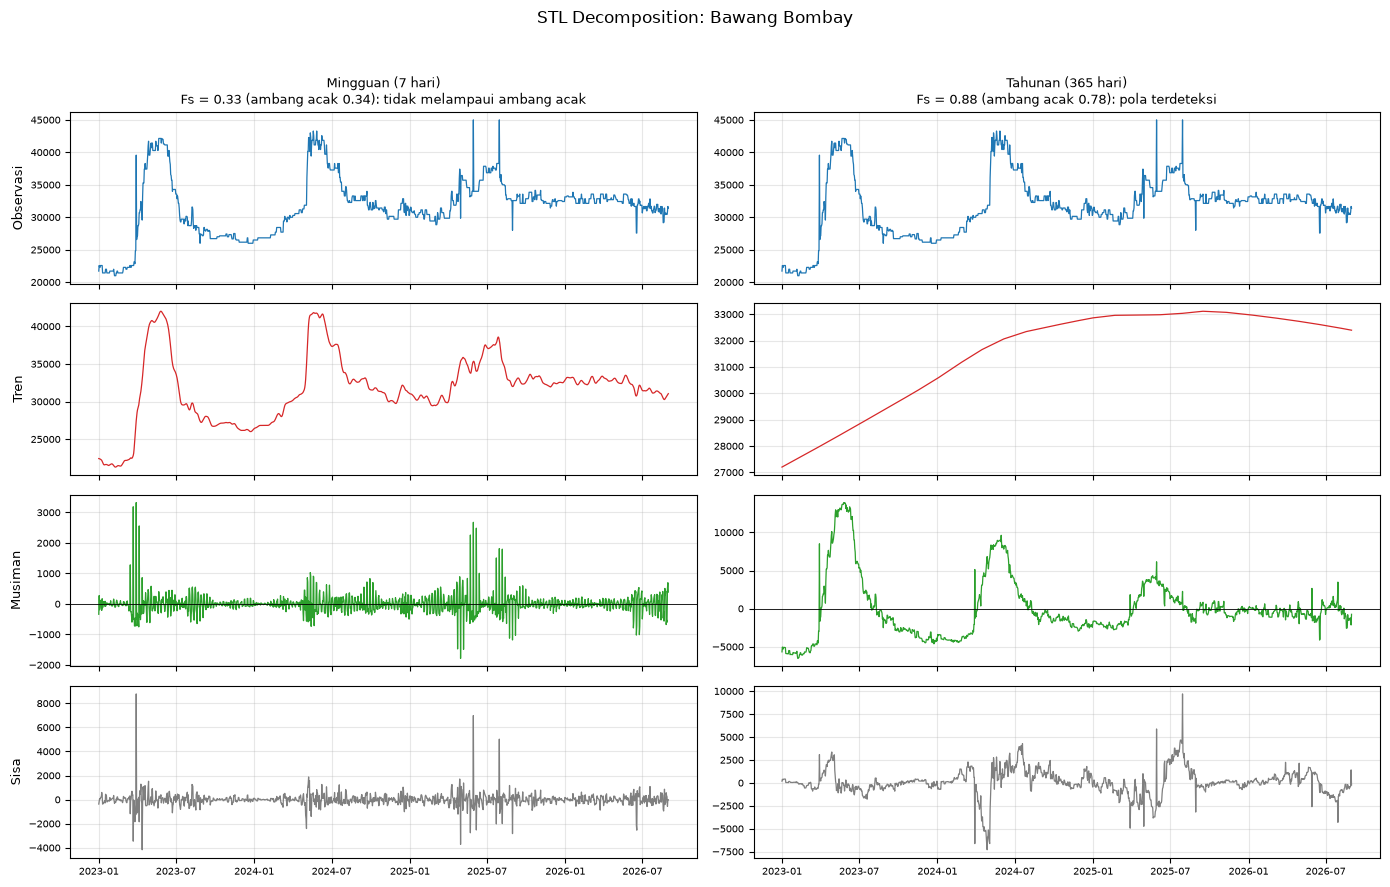

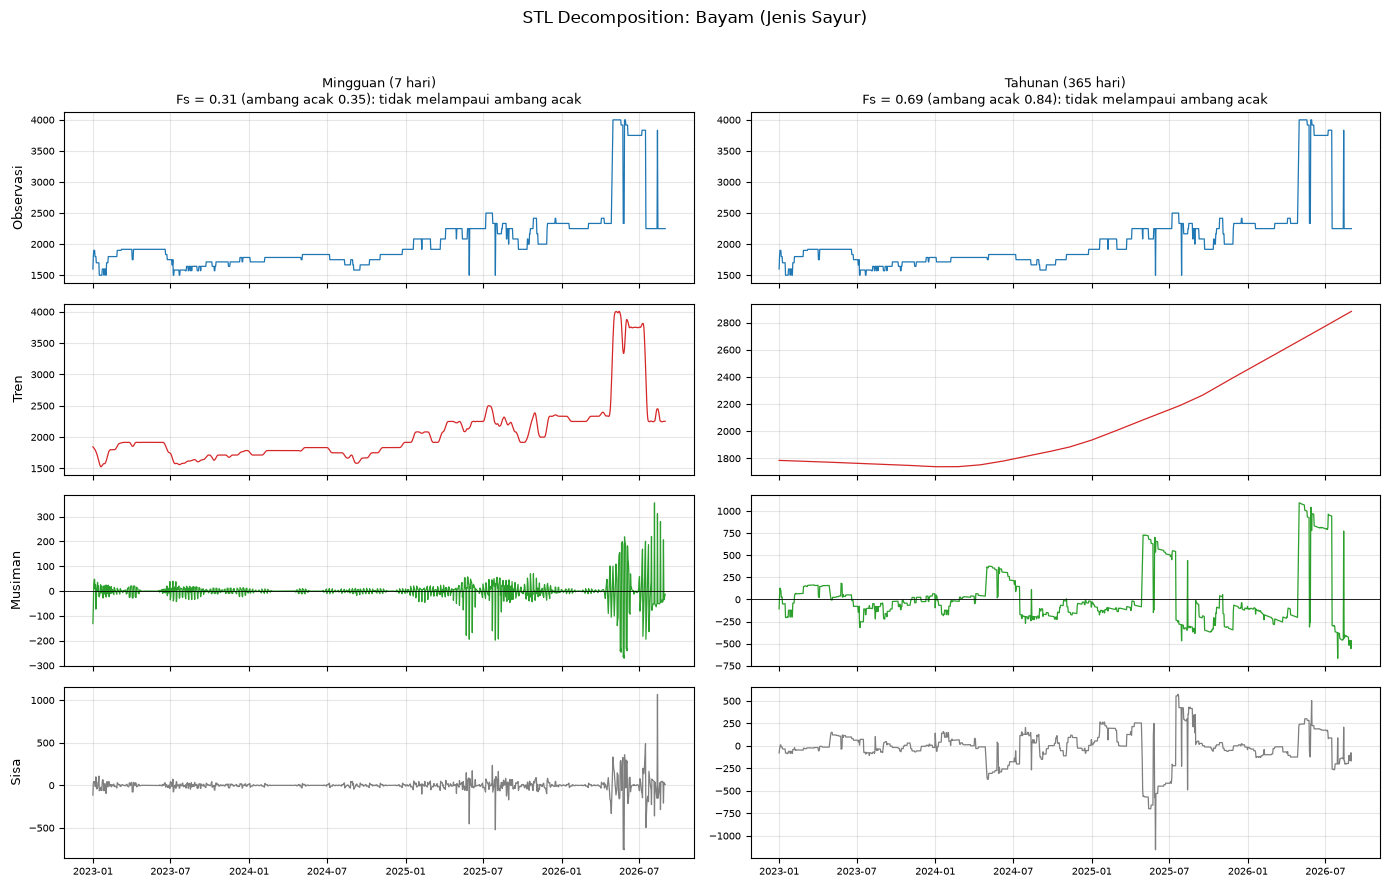

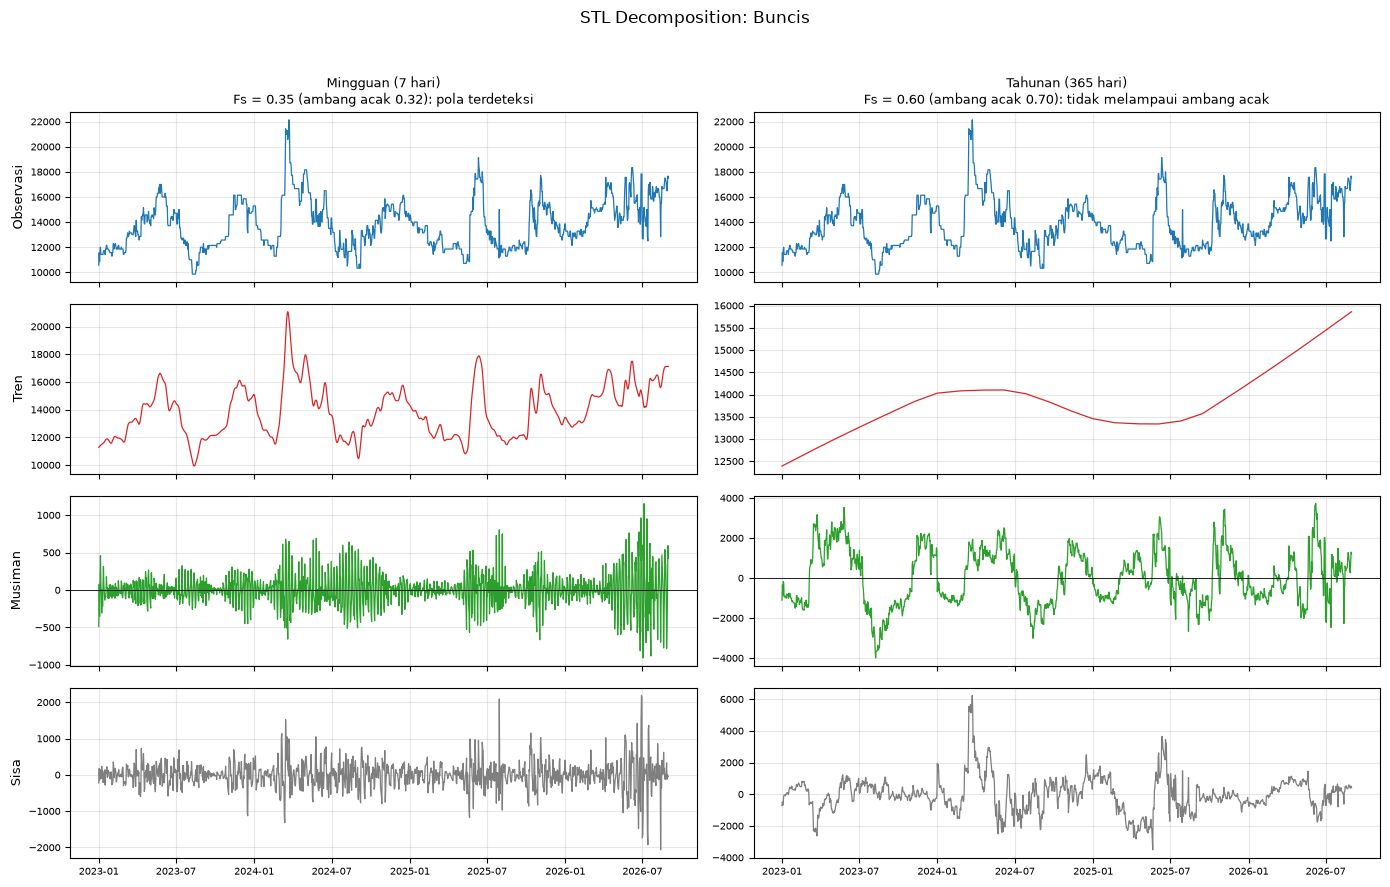

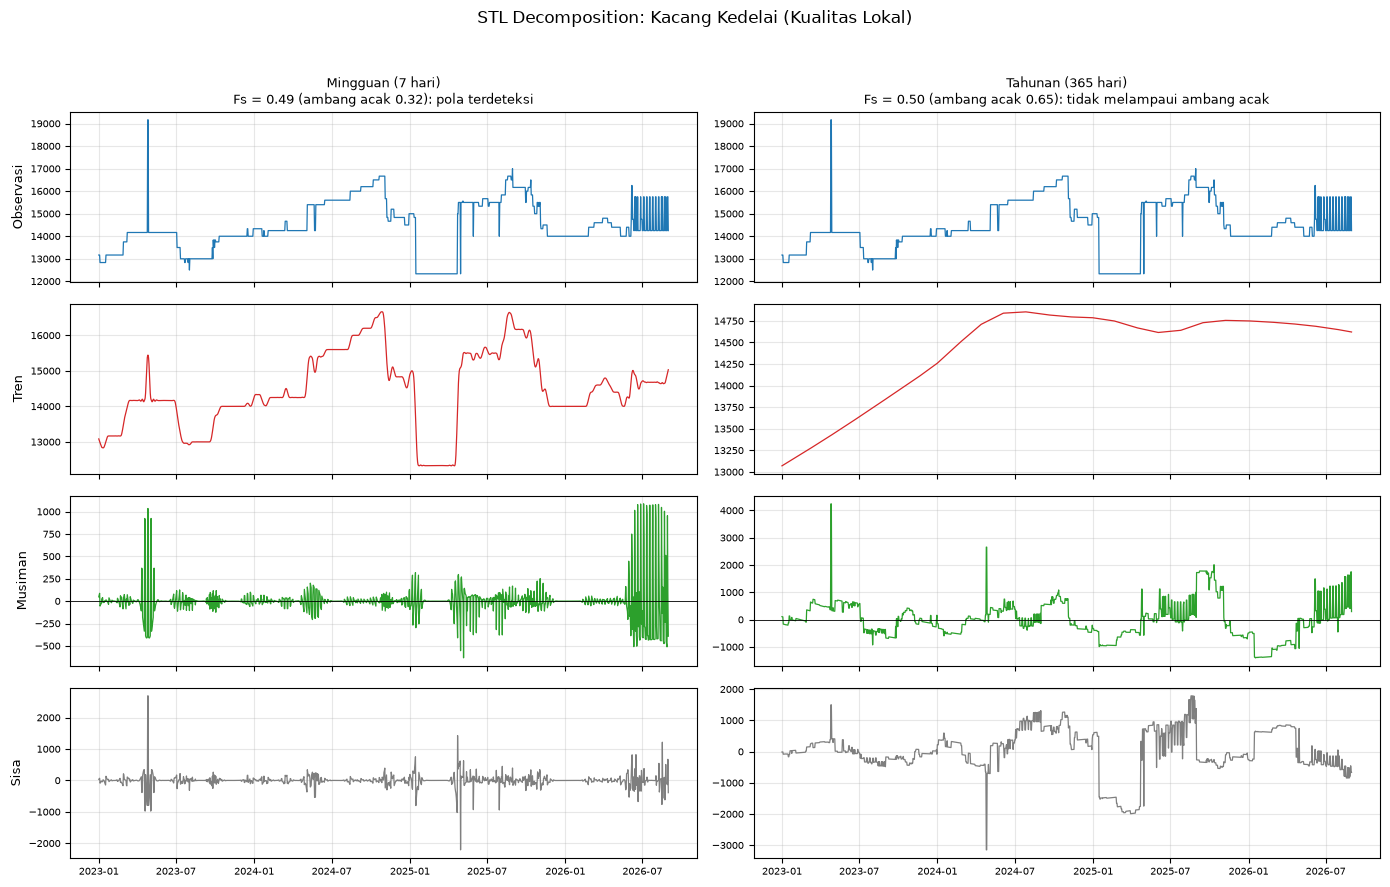

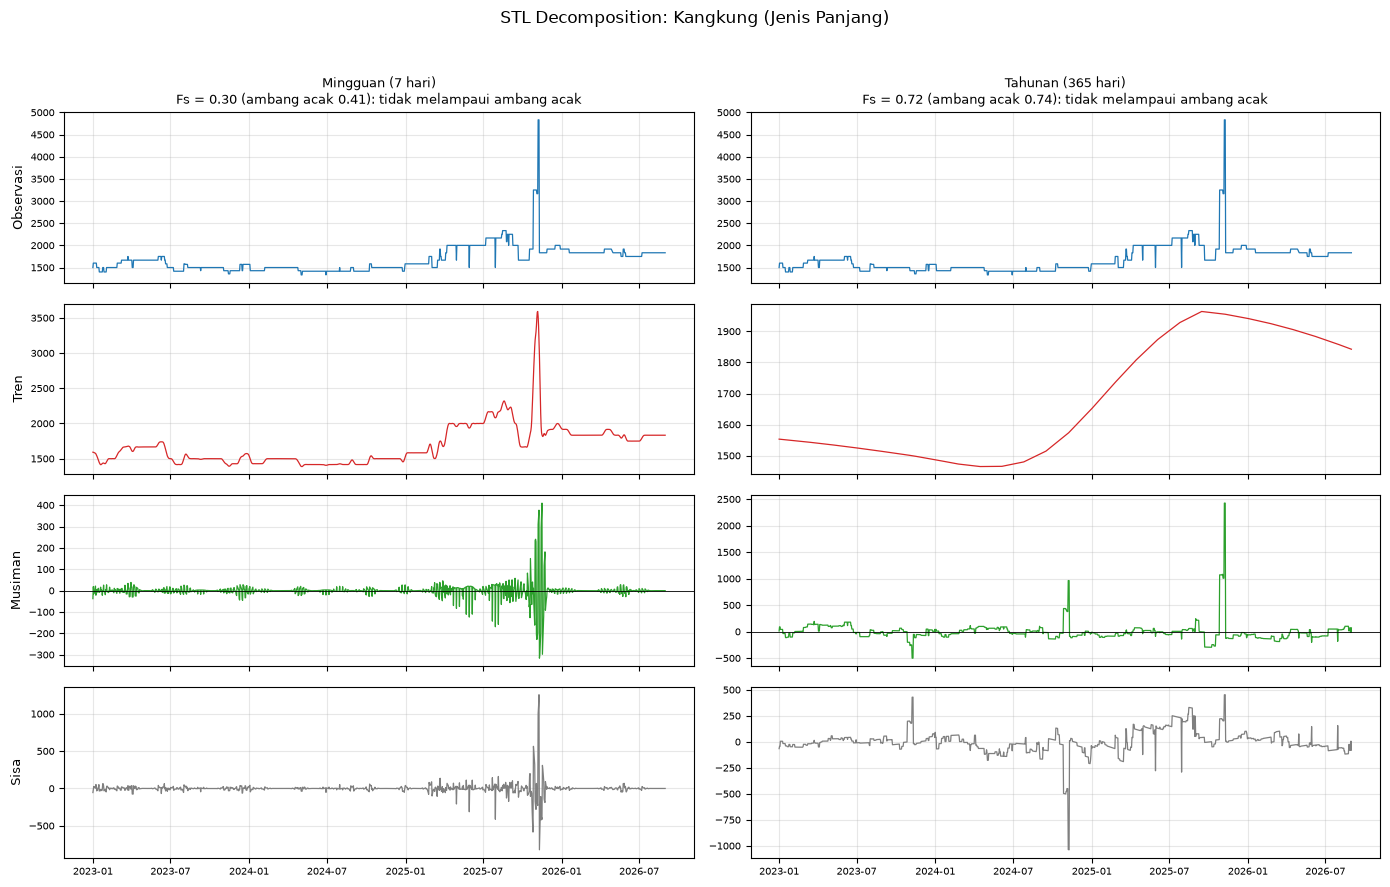

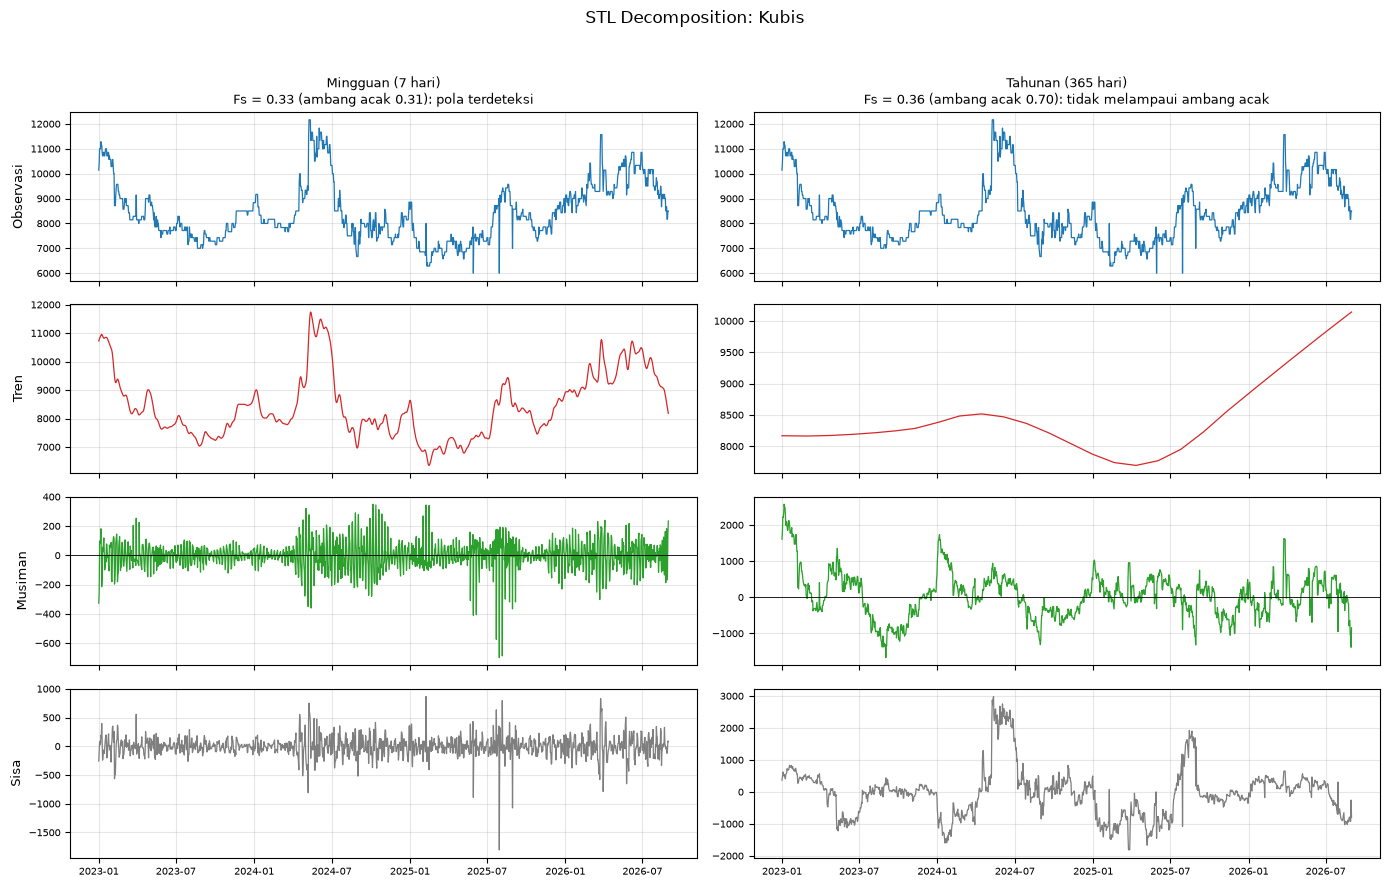

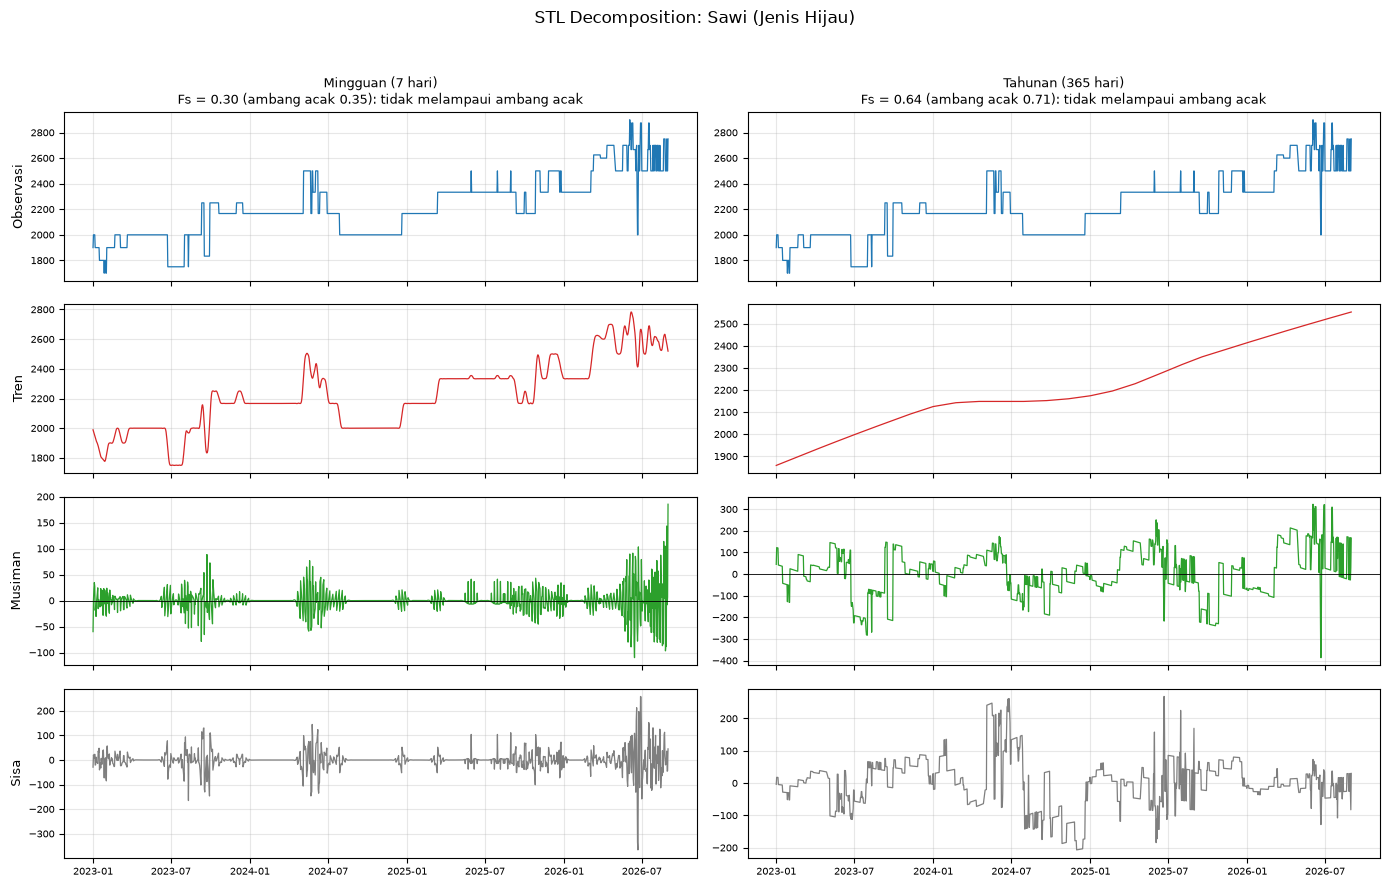

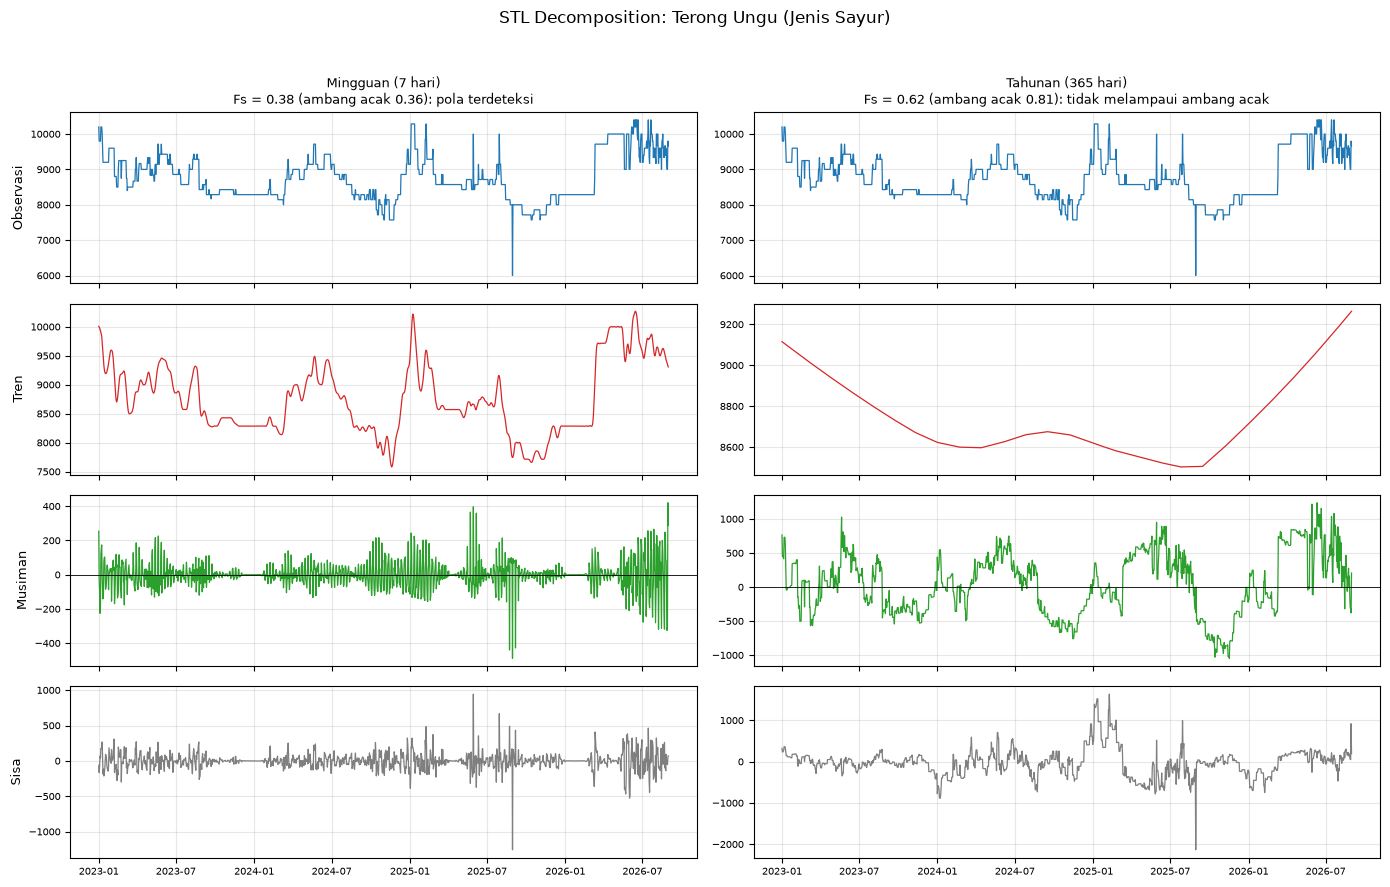

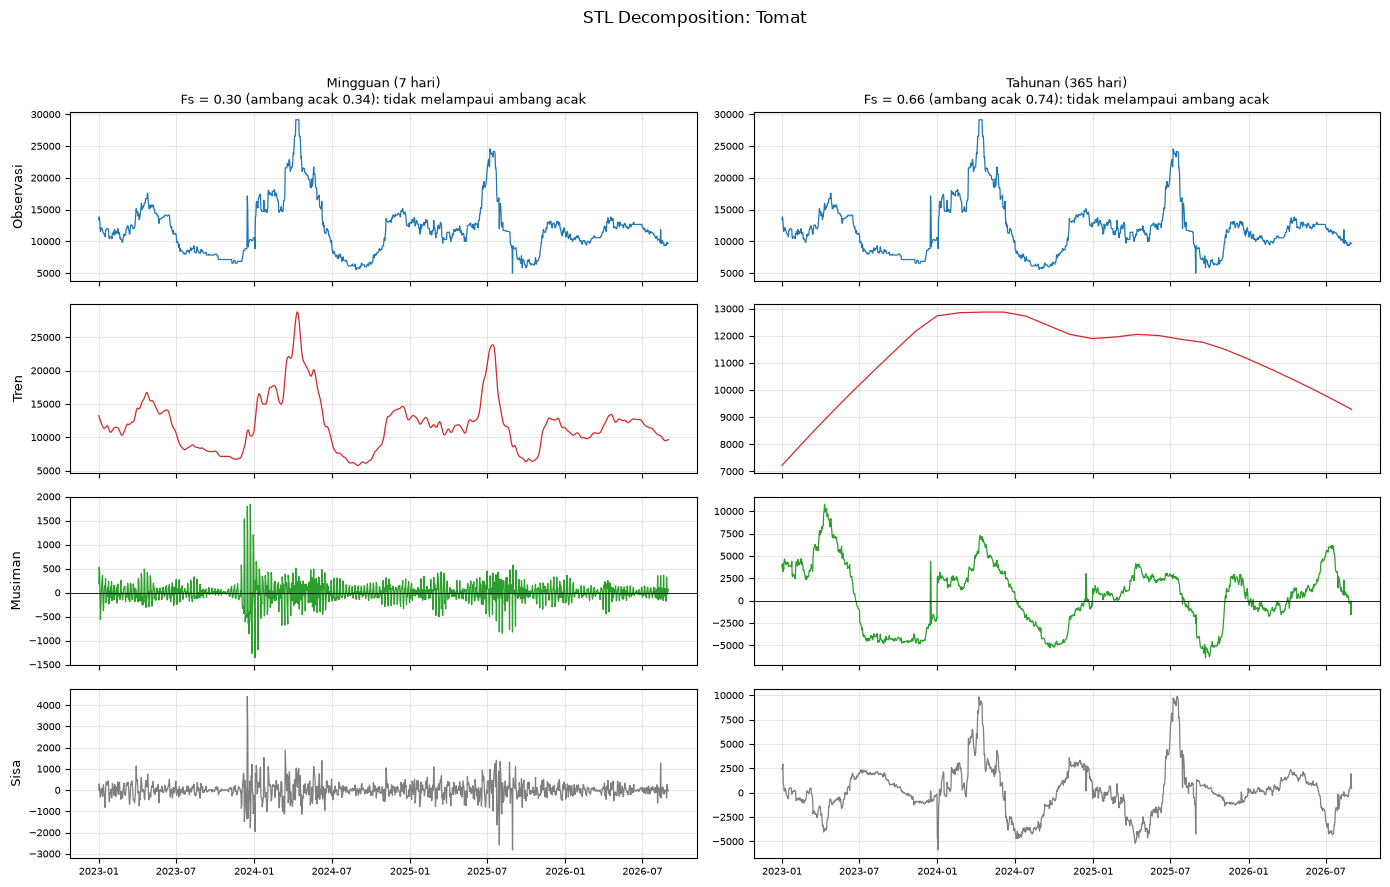

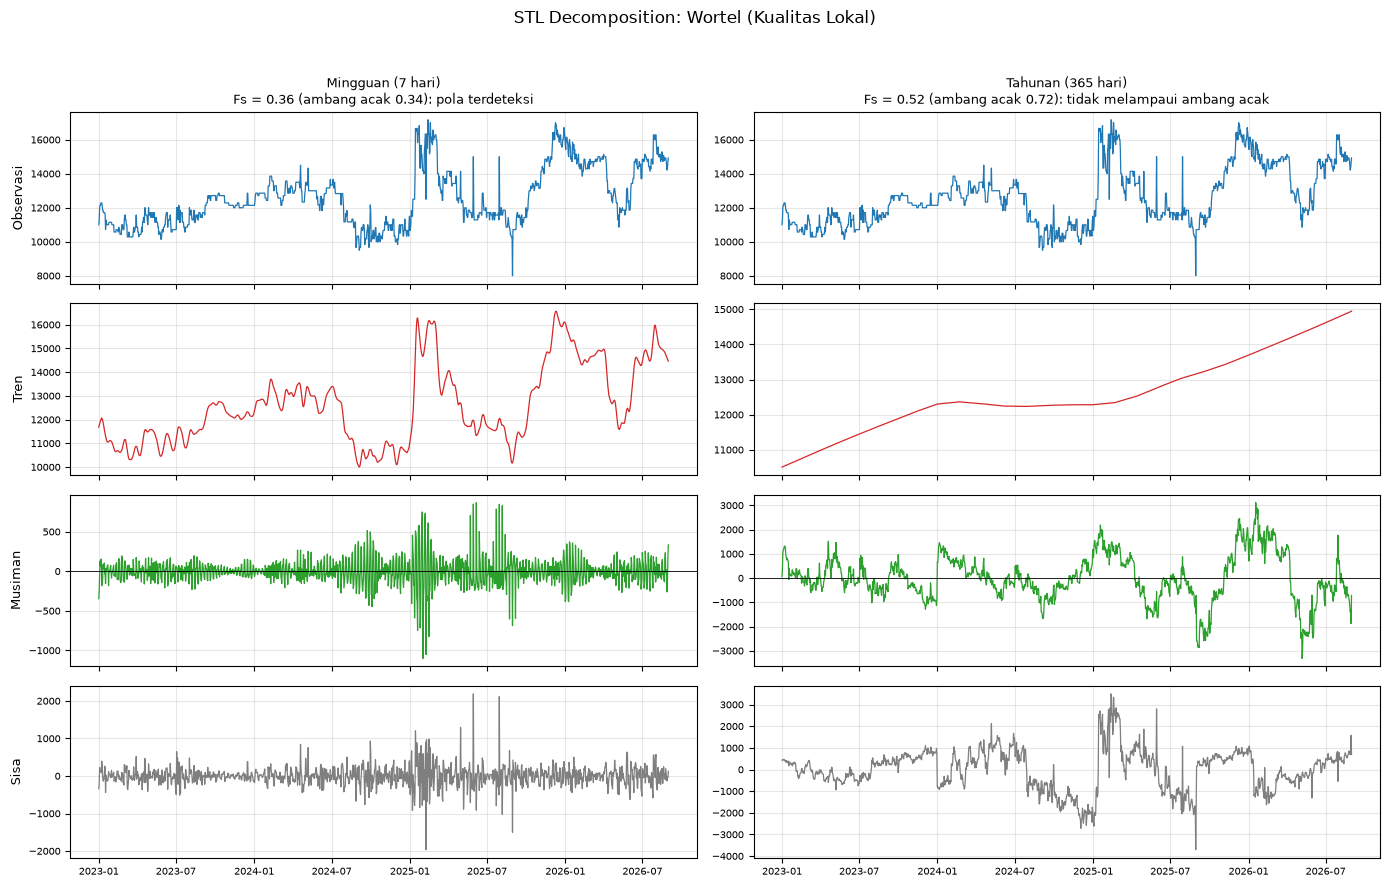

C:\Users\Eris Alfionita\AppData\Local\Temp\ipykernel_9548\3420252871.py:52: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  pos = res.seasonal.index.dayofweek if p == 7 else np.minimum(res.seasonal.index.dayofyear, 365)
C:\Users\Eris Alfionita\AppData\Local\Temp\ipykernel_9548\3420252871.py:52: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  pos = res.seasonal.index.dayofweek if p == 7 else np.minimum(res.seasonal.index.dayofyear, 365)
C:\Users\Eris Alfionita\AppData\Local\Temp\ipykernel_9548\3420252871.py:52: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  pos = res.seasonal.index.dayofweek if p == 7 else np.minimum(res.seasonal.index.dayofyear, 365)
C:\Users\Eris Alfionita\AppData\Local\Temp\ipykernel_9548\3420252871.py:52: 

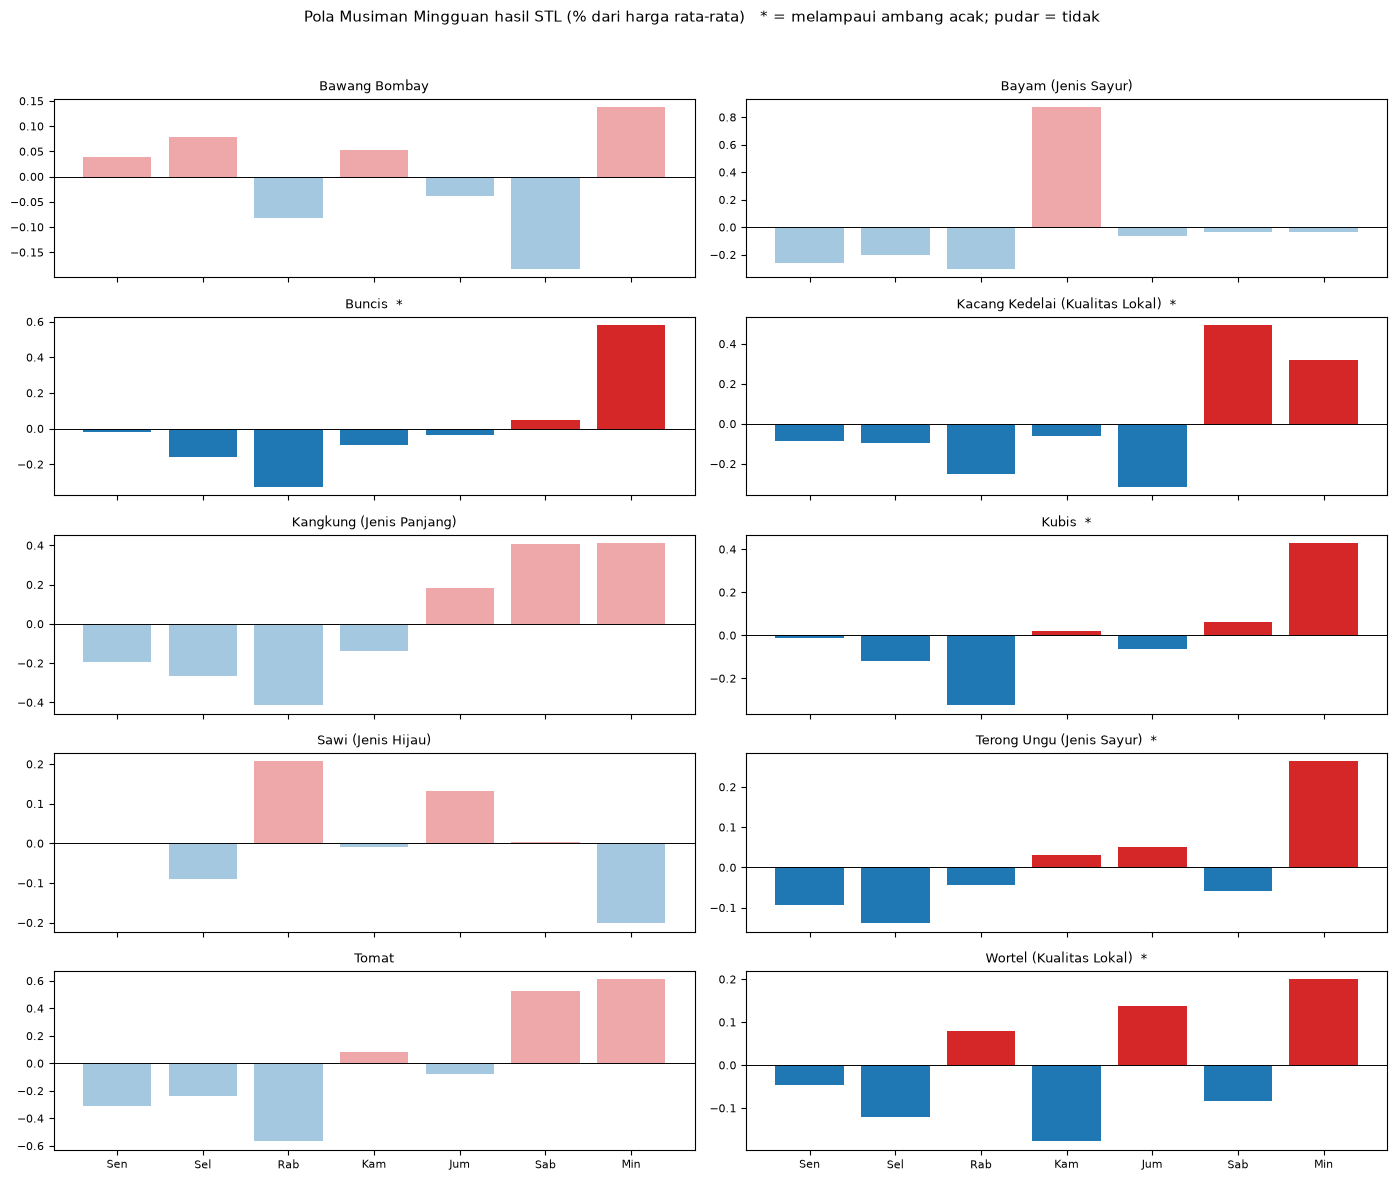

C:\Users\Eris Alfionita\AppData\Local\Temp\ipykernel_9548\3420252871.py:52: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  pos = res.seasonal.index.dayofweek if p == 7 else np.minimum(res.seasonal.index.dayofyear, 365)
C:\Users\Eris Alfionita\AppData\Local\Temp\ipykernel_9548\3420252871.py:52: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  pos = res.seasonal.index.dayofweek if p == 7 else np.minimum(res.seasonal.index.dayofyear, 365)
C:\Users\Eris Alfionita\AppData\Local\Temp\ipykernel_9548\3420252871.py:52: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  pos = res.seasonal.index.dayofweek if p == 7 else np.minimum(res.seasonal.index.dayofyear, 365)
C:\Users\Eris Alfionita\AppData\Local\Temp\ipykernel_9548\3420252871.py:52: 

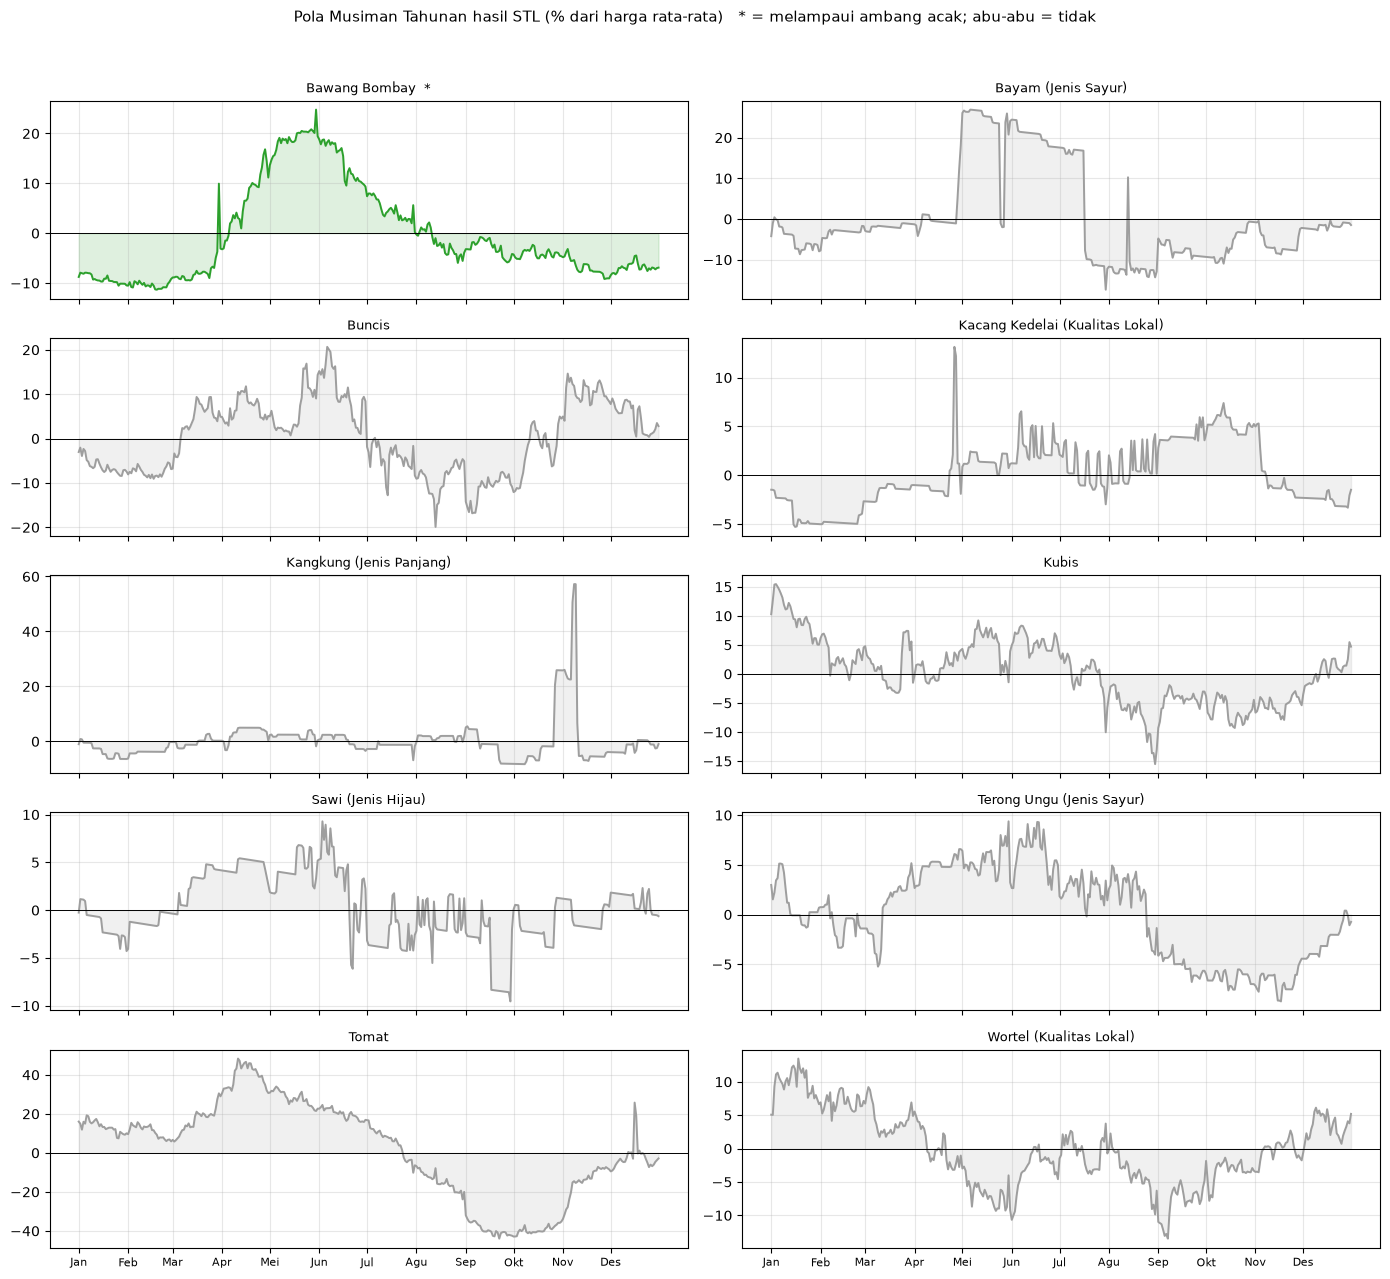

In [8]:
# ===== VISUAL STL DECOMPOSITION: PERIODE MINGGUAN (7) DAN TAHUNAN (365) =====
# Memakai stl_hasil dan stl_tabel dari sel STL sebelumnya, jadi tidak ada perhitungan ulang.
PERIODE_VISUAL = (7, 365)
JUDUL_PERIODE = {7: "Mingguan (7 hari)", 365: "Tahunan (365 hari)"}
KOMODITAS_TAMPIL = komoditas_list          # ubah menjadi daftar nama tertentu bila hanya ingin sebagian ditampilkan
(OUT_GAMBAR / "stl_mingguan_tahunan").mkdir(exist_ok=True)

# ---------- 1. Dekomposisi lengkap per komoditas (4 komponen x 2 periode) ----------
KOMPONEN = [("Observasi", "observed", "#1f77b4"), ("Tren", "trend", "#d62728"),
            ("Musiman", "seasonal", "#2ca02c"), ("Sisa", "resid", "#7f7f7f")]


def gambar_stl_dua_periode(nama):
    fig, axes = plt.subplots(4, len(PERIODE_VISUAL), figsize=(14, 9), sharex=True)
    for j, p in enumerate(PERIODE_VISUAL):
        res = stl_hasil.get((nama, p))
        if res is None:
            for i in range(4):
                axes[i, j].axis("off")
            axes[0, j].text(0.5, 0.5, f"{JUDUL_PERIODE[p]}: data kurang dari {MIN_SIKLUS * p} hari",
                            ha="center", transform=axes[0, j].transAxes)
            continue
        for i, (judul, atribut, warna) in enumerate(KOMPONEN):
            ax = axes[i, j]
            ax.plot(getattr(res, atribut).index, getattr(res, atribut).values, color=warna, linewidth=0.9)
            if atribut == "seasonal":
                ax.axhline(0, color="black", linewidth=0.6)
            ax.grid(alpha=0.3)
            ax.tick_params(labelsize=7)
            if j == 0:
                ax.set_ylabel(judul, fontsize=9)
        fs, amb = stl_tabel.at[nama, f"Fs_{p}"], stl_tabel.at[nama, f"ambang_{p}"]
        status = "pola terdeteksi" if musiman_ada(stl_tabel.loc[nama], p) else "tidak melampaui ambang acak"
        axes[0, j].set_title(f"{JUDUL_PERIODE[p]}\nFs = {fs:.2f} (ambang acak {amb:.2f}): {status}", fontsize=9)
    fig.suptitle(f"STL Decomposition: {nama}", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    return fig


for nama in KOMODITAS_TAMPIL:
    fig = gambar_stl_dua_periode(nama)
    aman = "".join(c if c.isalnum() else "_" for c in nama)
    fig.savefig(OUT_GAMBAR / "stl_mingguan_tahunan" / f"stl_{aman}.png", dpi=130, bbox_inches="tight")
    plt.show()

# ---------- 2. Ringkasan bentuk pola musiman semua komoditas ----------
# Komponen musiman STL dirata-ratakan per posisi dalam siklus dan dinyatakan sebagai % dari harga rata-rata.
def pola_siklus(nama, p):
    res = stl_hasil.get((nama, p))
    if res is None:
        return None
    pos = res.seasonal.index.dayofweek if p == 7 else np.minimum(res.seasonal.index.dayofyear, 365)
    return res.seasonal.groupby(pos).mean() / seri[nama].mean() * 100


n = len(KOMODITAS_TAMPIL)
baris_n = int(np.ceil(n / 2))

# 2a. Mingguan: batang per hari
fig, axes = plt.subplots(baris_n, 2, figsize=(14, 2.4 * baris_n), sharex=True)
axes = axes.ravel()
for ax, nama in zip(axes, KOMODITAS_TAMPIL):
    pola = pola_siklus(nama, 7)
    ada = musiman_ada(stl_tabel.loc[nama], 7)
    ax.bar(NAMA_HARI, pola.values, color=np.where(pola.values >= 0, "#d62728", "#1f77b4"), alpha=1 if ada else 0.4)
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set_title(f"{nama}" + ("  *" if ada else ""), fontsize=9)
    ax.tick_params(labelsize=8)
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("Pola Musiman Mingguan hasil STL (% dari harga rata-rata)   * = melampaui ambang acak; pudar = tidak", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(OUT_GAMBAR / "stl_pola_mingguan.png", dpi=150, bbox_inches="tight")
plt.show()

# 2b. Tahunan: kurva per hari dalam tahun
awal_bulan = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
fig, axes = plt.subplots(baris_n, 2, figsize=(14, 2.6 * baris_n), sharex=True)
axes = axes.ravel()
for ax, nama in zip(axes, KOMODITAS_TAMPIL):
    pola = pola_siklus(nama, 365)
    if pola is None:
        ax.set_title(f"{nama}: data < {MIN_SIKLUS * 365} hari", fontsize=9)
        continue
    ada = musiman_ada(stl_tabel.loc[nama], 365)
    ax.plot(pola.index, pola.values, color="#2ca02c" if ada else "#9e9e9e", linewidth=1.4)
    ax.axhline(0, color="black", linewidth=0.7)
    ax.fill_between(pola.index, 0, pola.values, color="#2ca02c" if ada else "#9e9e9e", alpha=0.15)
    ax.set_title(f"{nama}" + ("  *" if ada else ""), fontsize=9)
    ax.set_xticks(awal_bulan)
    ax.set_xticklabels(NAMA_BULAN, fontsize=8)
    ax.grid(alpha=0.3)
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("Pola Musiman Tahunan hasil STL (% dari harga rata-rata)   * = melampaui ambang acak; abu-abu = tidak", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(OUT_GAMBAR / "stl_pola_tahunan.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Persiapan dataset forecasting

Bagian ini akan menghasilkan tiga berkas data yang dibaca notebook backtest:
1. **Deret waktu harian** (`deret_waktu_harian.csv`): harga dan status (`asli` atau `interpolasi`) per komoditas.
2. **Fitur kalender** (`kalender_fitur.csv`): hari dalam minggu, bulan, akhir pekan, hari libur, dan jarak ke hari libur, untuk seluruh periode historis **dan** `KALENDER_KE_DEPAN` (7) hari ke depan, karena nilai fitur ini diketahui sebelumnya. Dengan demikian notebook backtest dan notebook ramalan final cukup membaca berkas ini tanpa menghitung ulang hari libur nasional dan akhir pekan.
3. **Dataset forecasting** (`dataset_forecasting.csv`): deret harian yang digabung dengan fitur kalender.

Profil gabungan (kualitas, tren, musiman) disimpan sebagai tabel di folder laporan. Kolom `musiman_dominan` pada profil tersebut bersifat deskriptif dan bukan masukan model. Penetapan `HORIZON`, pembagian train, validation, dan test, uji stasioneritas, serta fitur lag dan rolling akan dikerjakan pada notebook backtest agar tidak bocor ke data uji. Nilai `HORIZON` di notebook backtest tidak boleh melebihi `KALENDER_KE_DEPAN`, dan notebook tersebut akan memvalidasinya terhadap rentang tanggal pada `kalender_fitur.csv`. Ketiga berkas di atas merupakan seluruh luaran data notebook ini.

In [11]:
# ---------- 6a. Fitur kalender (historis + KALENDER_KE_DEPAN hari) ----------
tgl_awal = deret["tanggal"].min()
tgl_akhir = deret["tanggal"].max() + pd.Timedelta(days=KALENDER_KE_DEPAN)
kal = pd.date_range(tgl_awal, tgl_akhir, freq="D")
tahun = range(kal.min().year, kal.max().year + 1)

if HOLIDAYS_OK:
    libur = {pd.Timestamp(d) for d in holidays.country_holidays("ID", years=tahun)}
    print(f"Hari libur nasional dari paket `holidays`: {len(libur)} tanggal ({min(tahun)} s.d. {max(tahun)})")
else:
    libur = {pd.Timestamp(y, 1, 1) for y in tahun} | {pd.Timestamp(y, 12, 25) for y in tahun}
    print("PERINGATAN: paket `holidays` tidak terpasang, hanya 1 Jan dan 25 Des yang dipakai (pip install holidays).")

CAP = 30
libur_arr = np.array(sorted(libur), dtype="datetime64[D]")
tgl = kal.values.astype("datetime64[D]")
i_next = np.searchsorted(libur_arr, tgl, side="left")
i_prev = np.searchsorted(libur_arr, tgl, side="right") - 1
ke_depan = np.where(i_next < len(libur_arr),
                    (libur_arr[np.minimum(i_next, len(libur_arr) - 1)] - tgl).astype(int), CAP)
dari_belakang = np.where(i_prev >= 0, (tgl - libur_arr[np.maximum(i_prev, 0)]).astype(int), CAP)

fitur = pd.DataFrame({
    "tanggal": kal,
    "tahun": kal.year, "kuartal": kal.quarter, "bulan": kal.month,
    "minggu_tahun": kal.isocalendar().week.astype(int).values,
    "hari_dalam_bulan": kal.day, "hari_dalam_minggu": kal.dayofweek,
    "akhir_pekan": (kal.dayofweek >= 5).astype(int),
    "libur": kal.isin(list(libur)).astype(int),
    "hari_ke_libur_berikut": np.minimum(ke_depan, CAP),
    "hari_sejak_libur": np.minimum(dari_belakang, CAP),
})

# ---------- 6b. Dataset forecasting (harga dibulatkan ke rupiah) ----------
# Pembulatan hanya pada data luaran; deret asli tidak diubah.
deret_bulat = deret.assign(harga=deret["harga"].round(0).astype("int64"))
dataset = deret_bulat.merge(fitur, on="tanggal", how="left")
assert dataset[fitur.columns].notna().all().all(), "Ada fitur kalender yang kosong"
assert (dataset["harga"] > 0).all(), "Ada harga bernilai nol setelah pembulatan"

# ---------- 6c. Profil gabungan ----------
# Catatan: musiman_dominan bersifat deskriptif, bukan masukan model.
profil_lengkap = profil.join(tren).join(stl_tabel)

# ---------- Simpan ----------
deret_bulat.to_csv(OUT_DATA / "deret_waktu_harian.csv", index=False, encoding="utf-8-sig")
dataset.to_csv(OUT_DATA / "dataset_forecasting.csv", index=False, encoding="utf-8-sig")
fitur.to_csv(OUT_DATA / "kalender_fitur.csv", index=False, encoding="utf-8-sig")
profil_lengkap.to_csv(OUT_TABEL / "profil_deret_waktu.csv", encoding="utf-8-sig")
stl_tabel.to_csv(OUT_TABEL / "stl_kekuatan_musiman.csv", encoding="utf-8-sig")
tren.to_csv(OUT_TABEL / "tren_dan_pola_musiman.csv", encoding="utf-8-sig")

print(f"\nTersimpan di {OUT_DATA}:")
for f in ["deret_waktu_harian", "dataset_forecasting", "kalender_fitur"]:
    print(f"  - {f}.csv")
print(f"Tersimpan di {OUT_TABEL}: profil_deret_waktu, stl_kekuatan_musiman, tren_dan_pola_musiman")
print("Catatan: harga pada berkas data dibulatkan ke rupiah terdekat.")
print("Catatan: kolom musiman_dominan bersifat deskriptif, bukan masukan model.")

Hari libur nasional dari paket `holidays`: 69 tanggal (2023 s.d. 2026)

Tersimpan di D:\STUDY\SEMESTER 5\magang\proyek\siperkom-dashboard\data\processed\forecasting:
  - deret_waktu_harian.csv
  - dataset_forecasting.csv
  - kalender_fitur.csv
Tersimpan di D:\STUDY\SEMESTER 5\magang\proyek\siperkom-dashboard\reports\tables\forecasting: profil_deret_waktu, stl_kekuatan_musiman, tren_dan_pola_musiman
Catatan: harga pada berkas data dibulatkan ke rupiah terdekat.
Catatan: kolom musiman_dominan bersifat deskriptif, bukan masukan model.


C:\Users\Eris Alfionita\AppData\Local\Temp\ipykernel_9548\3059584045.py:27: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "hari_dalam_bulan": kal.day, "hari_dalam_minggu": kal.dayofweek,
C:\Users\Eris Alfionita\AppData\Local\Temp\ipykernel_9548\3059584045.py:28: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "akhir_pekan": (kal.dayofweek >= 5).astype(int),


In [14]:
# dataset = dataset_forecasting.csv
dataset.head(5)

,tanggal,komoditas,harga,status,tahun,kuartal,bulan,minggu_tahun,hari_dalam_bulan,hari_dalam_minggu,akhir_pekan,libur,hari_ke_libur_berikut,hari_sejak_libur
0,2023-01-01,Bawang Bombay,21714,asli,2023,1,1,52,1,6,1,1,0,0
1,2023-01-02,Bawang Bombay,22571,asli,2023,1,1,1,2,0,0,0,20,1
2,2023-01-03,Bawang Bombay,22286,asli,2023,1,1,1,3,1,0,0,19,2
3,2023-01-04,Bawang Bombay,22286,asli,2023,1,1,1,4,2,0,0,18,3
4,2023-01-05,Bawang Bombay,22571,asli,2023,1,1,1,5,3,0,0,17,4


In [15]:
# deret_bulat = deret_waktu_harian.csv
deret_bulat.head(5)

,tanggal,komoditas,harga,status
0,2023-01-01,Bawang Bombay,21714,asli
1,2023-01-02,Bawang Bombay,22571,asli
2,2023-01-03,Bawang Bombay,22286,asli
3,2023-01-04,Bawang Bombay,22286,asli
4,2023-01-05,Bawang Bombay,22571,asli


In [17]:
# stl_tabel = stl_kekuatan_musiman.csv
stl_tabel.head(10)


,Fs_7,ambang_7,amplitudo_7_pct,Fs_30,ambang_30,amplitudo_30_pct,Fs_365,ambang_365,amplitudo_365_pct,musiman_dominan
komoditas,,,,,,,,,,
Bawang Bombay,0.333,0.345,16.15,0.210,0.267,12.01,0.878,0.779,64.62,periode 365
Bayam (Jenis Sayur),0.309,0.349,30.45,0.387,0.311,88.91,0.689,0.841,85.52,periode 30
Buncis,0.350,0.320,14.89,0.155,0.244,32.42,0.603,0.696,55.71,periode 7
Kacang Kedelai (Kualitas Lokal),0.490,0.324,11.91,0.242,0.250,15.47,0.500,0.652,39.05,periode 7
Kangkung (Jenis Panjang),0.297,0.412,43.11,0.142,0.368,28.34,0.720,0.739,173.90,tidak jelas
Kubis,0.331,0.314,12.41,0.197,0.254,14.67,0.359,0.705,50.25,periode 7
Sawi (Jenis Hijau),0.304,0.349,13.33,0.250,0.301,15.12,0.642,0.706,32.02,tidak jelas
Terong Ungu (Jenis Sayur),0.383,0.357,10.38,0.312,0.282,11.81,0.623,0.805,26.09,periode 30
Tomat,0.296,0.339,26.73,0.243,0.278,41.84,0.655,0.743,143.43,tidak jelas
